# LULC from Sentinel-1, 5th iteration: three-map label vote

**The finding that led here** (`reports/2026-11-05 4th iteration and label disagreement.md`). The 4th iteration added data (17 new sites, 2022-2024 radar). Overall mIoU did not move, but the classes traded places: Crop fields +0.06 and Grassland +0.05 IoU, Bare ground, Man-made and Snow & ice -0.05 to -0.06. The prototype then showed why: the global maps **define the same land differently**.

| Test site | Our label (WorldCover) | Esri (Sentinel-2) | Model |
|---|---|---|---|
| Kano farmland, Nigeria | farmland | 95 % rangeland, 0 % crops | 81 % Crop fields |
| Chilean lakes (pasture) | grassland | 64 % crops | 74 % Grassland |

WorldCover and Dynamic World agree on only 55.6 % of Grassland, 64.3 % of Bare ground and 70.2 % of Crop fields pixels. On a disputed pixel the model learned the WorldCover class at half weight; new data only moved the boundaries between these classes. **The labels, not the network, limit these classes.**

**The fix tested here: a majority vote of three independent maps.** WorldCover (Sentinel-1 + 2), Dynamic World (Sentinel-2, Google) and Esri 10 m LULC (Sentinel-2, Impact Observatory) of the same year. A pixel's training label is the class at least two maps agree on; those pixels count fully. Where all three differ, the WorldCover class stays at half weight, as before. The model input stays **Sentinel-1 only**.

| Experiment | Labels | Data |
|---|---|---|
| `V0_worldcover` | WorldCover, Dynamic World agreement (= `Iter2_Test_1_Full`) | 2021, earlier sites |
| `V1_vote` | three-map vote | 2021, earlier sites |
| `V2_vote_all_data` | three-map vote | + 2022-2024 and the new sites (later years now get labels of their own year from Dynamic World and Esri) |

**Three scores, because the "truth" itself is in question:**
- **WorldCover score** (as in all earlier runs: WorldCover pixels confirmed by Dynamic World): comparable with every earlier iteration;
- **vote score**: pixels where at least two of the three maps agree, labelled with that class: the best available reference;
- **tolerant score**: a prediction counts as correct if it matches any of the three maps (pixels where WorldCover has a class): how much of the "error" is only disagreement between the maps.

**Decision:** by mean val mIoU on the **vote** labels (every configuration is scored on the same labels); a configuration counts only if it beats `V0_worldcover` by more than `NOISE`. 2 seeds per configuration.

**Caveat:** Esri is now part of the training labels, so the prototype's Esri check is no longer fully independent for a model trained on the vote; the prototype therefore shows WorldCover and Dynamic World as references too.

Sections 2-7 are those of `Notebooks/4th_iteration_multiyear.ipynb`, with the vote labels loaded next to the WorldCover labels.


## Glossary: new terms in this notebook

| Term | Meaning |
|---|---|
| SGD with momentum | stochastic gradient descent that keeps a running average of past gradients (momentum 0.9) and steps along it; Nesterov evaluates the gradient one step ahead. One global learning rate |
| AdamW | Adam (a learning rate per weight, from running averages of the gradient and its square) with weight decay applied directly to the weights instead of through the gradient |
| Lovász-softmax | a loss that optimises the IoU of each class directly (Berman et al. 2018); cross-entropy optimises per-pixel accuracy |
| seed, spread | see `3rd_iteration_encoders.ipynb`: the random start and the best-minus-worst difference over seeds |

## 1. Settings and hardware check

- `EXPERIMENTS`: the configurations (table above); new key `labels`: `"worldcover"` or `"vote"`.
- `DECIDE_BY`: the val score used to choose (`"val vote mIoU"`).
- The class-bias search of the 4th iteration found no gain (best offset 0 for Water and Man-made) and is switched off (`BIAS_CLASSES = []`).


In [1]:
RUN_NAME = "Iter5_LabelVote"
NOTEBOOK = "Notebooks/5th_iteration_label_vote.ipynb"
ENCODER = "resnet34"   # the encoder of Iter2_Test_1_Full; the 3rd iteration found no encoder better beyond noise

ALL_YEARS = (2021, 2022, 2023, 2024)
EXPERIMENTS = {
    "V0_worldcover":    {},                                                      # reference = Iter2_Test_1_Full
    "V1_vote":          dict(labels="vote"),                                     # three-map vote, 2021 data
    "V2_vote_all_data": dict(labels="vote", years=ALL_YEARS, new_sites=True),    # vote + all 4th-iteration data
}
DECIDE_BY = "val vote mIoU"   # every configuration is scored on the same (vote) val labels

VARIANT_NAME, VARIANT = "month_year", dict(n_months=1)   # the input of Iter2_Test_1_Full, fixed in every experiment
SEEDS = [42, 7]          # every configuration is trained once per seed (one run alone carries about +-0.02 mIoU noise)
NOISE = 0.02             # a configuration must beat the reference by more than this (mean val mIoU over the seeds)

# Every key of BASE can be changed by an experiment
BASE = dict(encoder=ENCODER, pretrained=True,
            optimizer="adamw", lr=6e-4, weight_decay=0.05,       # sgd: Nesterov momentum 0.9
            lovasz_weight=0.5,                                   # 0 = cross-entropy only
            disagree_weight=0.5,                                 # loss weight where WorldCover and Dynamic World disagree
            label_smoothing=0.1,
            bootstrap_beta=1.0,                                  # < 1: soft bootstrapping
            years=(2021,),                                       # radar years of the training patches
            new_sites=False,                                     # draw the 4th-iteration sites
            labels="worldcover")                                 # "worldcover" or "vote" (three-map vote)
ONLY = None              # e.g. ["Y0_reference"] to run a subset; None = all

BIAS_CLASSES = []                                                # 4th iteration: no gain, switched off
BIAS_GRID = [-1.5, -1.0, -0.75, -0.5, -0.25, 0.0, 0.25, 0.5]     # log-probability offsets tried per class
BIAS_MIN_GAIN = 0.002                                            # keep an offset only if val mIoU rises by more

MAX_EPOCHS = 40
VAL_MONTHS = list(range(12))
VAL_EVERY = 2
PATIENCE = 10
SAMPLES_PER_EPOCH = 2500
WARMUP_EPOCHS = 1
EMA_DECAY = 0.99
DROPOUT = 0.2
MONTH_DROP = 0.3
LOVASZ_SAMPLE = 0.25
CROP_JITTER = 128
SEED = SEEDS[0]          # data-side randomness before training; every run sets its own seed

CONFIGS = {name: BASE | change for name, change in EXPERIMENTS.items() if ONLY is None or name in ONLY}
REFERENCE = next(iter(EXPERIMENTS))
assert not EXPERIMENTS[REFERENCE], "the first experiment must be the reference (no changes)"
for name, cfg in CONFIGS.items():
    print(f"{name:24}", {k: v for k, v in cfg.items() if v != BASE[k]} or "reference: Iter2_Test_1_Full settings")
print(f"{len(CONFIGS)} configurations x {len(SEEDS)} seeds = {len(CONFIGS) * len(SEEDS)} runs, up to {MAX_EPOCHS} epochs each")


V0_worldcover            reference: Iter2_Test_1_Full settings
V1_vote                  {'labels': 'vote'}
V2_vote_all_data         {'years': (2021, 2022, 2023, 2024), 'new_sites': True, 'labels': 'vote'}
3 configurations x 2 seeds = 6 runs, up to 40 epochs each


In [2]:
import subprocess, sys
try:
    import rasterio
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "rasterio"])
    import rasterio

import json, math, os, shutil, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# The notebook lives in Notebooks/; data and weights live at the repository root.
ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA_DIRS = [ROOT / "Dataset_2nd_iteration", Path("../input")]
OUT = ROOT / "Weights" / RUN_NAME
if OUT.exists() and any(OUT.iterdir()):
    OUT = OUT.with_name(f"{RUN_NAME}_{time.strftime('%Y%m%d_%H%M%S')}")
    print(f"Weights/{RUN_NAME} already has files, saving to {OUT} instead")


def s1_preprocessing(root):
    first = next((root / "s1").glob("*.tif"), None)
    if first is None:
        return ""
    with rasterio.open(first) as src:
        return src.tags().get("preprocessing", "")


def find_data_root():
    """The first dataset with a patch index whose radar tiles are terrain-flattened (2nd-iteration pipeline)."""
    for base in DATA_DIRS:
        if base.exists():
            for hit in sorted(base.rglob("train_patches.csv")):
                root = hit.parent.parent
                if "gamma0" in s1_preprocessing(root):
                    return root
                print("skipping (not built by the 2nd-iteration pipeline):", root)
    raise FileNotFoundError("Dataset_2nd_iteration not found: build it with data_pipeline/ (see data_pipeline/README.md)")


DATA = find_data_root()
S1_PREPROCESSING = s1_preprocessing(DATA)
RUNS_DIR = OUT / "runs"  # weights and history of every run; the best run is copied to OUT / best_model.pt
RUNS_DIR.mkdir(parents=True, exist_ok=True)
print("data:", DATA, "| output:", OUT.resolve())
print("radar preprocessing:", S1_PREPROCESSING)


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


Weights/Iter5_LabelVote already has files, saving to /home/jovyan/vault/LULC-semantic-Model/Weights/Iter5_LabelVote_20261106_143525 instead
data: /home/jovyan/vault/LULC-semantic-Model/Dataset_2nd_iteration | output: /home/jovyan/vault/LULC-semantic-Model/Weights/Iter5_LabelVote_20261106_143525
radar preprocessing: S1_GRD IW VV+VH asc+desc; gamma0 terrain flattening (Vollrath 2020 volume model, GLO-30); layover/shadow/incidence 31-45 deg masked; monthly linear mean; dB; no spatial filter


### Hardware check

Unchanged from the 1st iteration (section 1 there explains every rule): bfloat16 on Ampere and newer, float16 + `GradScaler` on T4; batch 64 with ≥ 24 GB GPU memory, else 32; no DataLoader workers when `/dev/shm` is small.

In [3]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CPU_COUNT = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()
SHM_GB = shutil.disk_usage("/dev/shm").total / 1e9 if Path("/dev/shm").exists() else None

if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    GPU_NAME, GPU_MEM_GB, CAPABILITY = props.name, props.total_memory / 1e9, (props.major, props.minor)
else:
    GPU_NAME, GPU_MEM_GB, CAPABILITY = "none", 0.0, (0, 0)

USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.bfloat16 if CAPABILITY >= (8, 0) else torch.float16
USE_SCALER = USE_AMP and AMP_DTYPE == torch.float16
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

BATCH = 64 if GPU_MEM_GB >= 24 else 32
GPU_TRAIN_RESERVE_GB = 12 if BATCH == 64 else 7   # ResNet-34 only: the 2nd-iteration value, so all years fit

# DataLoader workers hand batches over through shared memory (/dev/shm). Docker containers often
# give it only 64 MB, which kills the workers with "Bus error"; then load in the main process.
NUM_WORKERS = 0 if SHM_GB is not None and SHM_GB < 1 else min(8, CPU_COUNT)

print(f"GPU: {GPU_NAME} | {GPU_MEM_GB:.0f} GB | compute capability {CAPABILITY[0]}.{CAPABILITY[1]}")
print(f"CPU cores: {CPU_COUNT} | /dev/shm: {'n/a' if SHM_GB is None else f'{SHM_GB:.2f} GB'}")
print(f"mixed precision: {str(AMP_DTYPE).split('.')[-1] if USE_AMP else 'off'}{' + GradScaler' if USE_SCALER else ''}"
      f" | batch {BATCH} | DataLoader workers {NUM_WORKERS} (only used if the data does not fit on the GPU)")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| rasterio", rasterio.__version__)

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition | 102 GB | compute capability 12.0
CPU cores: 96 | /dev/shm: 0.07 GB
mixed precision: bfloat16 | batch 64 | DataLoader workers 0 (only used if the data does not fit on the GPU)
torch 2.9.1+cu128 | torchvision 0.24.1+cu128 | rasterio 1.4.4


### Dataset constants

- **Radar values** are uint8 codes: `dB = code * 0.2 - 35`, code 0 = no data (also layover and shadow).
- **Classes** (7; 1st iteration: 8):

| Class | Includes | WorldCover |
|---|---|---|
| Man-made | buildings, roads, paved yards, railways | 50 |
| Crop fields | land ploughed and harvested each year | 40 |
| Trees | forest, orchards, plantations, mangrove | 10, 95 |
| Grassland | pasture, meadows, steppe, shrub and scrub, marsh | 20, 30, 90 |
| Bare ground | desert, rock, sand, sparse vegetation | 60, 100 |
| Water | lakes, rivers, sea | 80 |
| Snow & ice | glaciers, permanent snow | 70 |

- **Label code** (one int16 array per tile, so labels and agreement travel together through cropping, flips and the GPU):
  - `0 ... 6`: class index, WorldCover and Dynamic World agree;
  - `7 ... 13`: class index + 7, only WorldCover (the maps disagree);
  - `-1`: no WorldCover data (ignored).

  `split_label` turns a code into the class index and the agreement mask.

In [4]:
CLASS_NAMES = ["Man-made", "Crop fields", "Trees", "Grassland", "Bare ground", "Water", "Snow & ice"]
CLASS_COLORS = ["#e31a1c", "#ffd92f", "#1a9850", "#a6d96a", "#bf812d", "#2c7fb8", "#dfe9f0"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
N_CLASSES = len(CLASS_NAMES)
IGNORE = -1
PATCH = 256
DB_MIN, DB_STEP = -35.0, 0.2

DB_LUT = (np.arange(256, dtype=np.float32) * DB_STEP + DB_MIN)
DB_LUT[0] = np.nan

CMAP = ListedColormap(["#000000"] + CLASS_COLORS)
LEGEND = [Patch(color=c, label=n) for n, c in zip(["no label"] + CLASS_NAMES, ["#000000"] + CLASS_COLORS)]


def label_classes(y):
    """numpy label codes -> class index (IGNORE where no label)."""
    return np.where(y >= 0, y % N_CLASSES, IGNORE)


def split_label(y):
    """torch label codes -> (class index or IGNORE, mask of pixels where both label maps agree)."""
    target = torch.where(y >= 0, y % N_CLASSES, torch.full_like(y, IGNORE))
    return target, (y >= 0) & (y < N_CLASSES)

## 2. Load the data

Same layout as the 2nd iteration: 1024 x 1024 px tiles (10.24 km), 12 months x 2 polarisations, splits by site. Train keeps the full tiles in memory (random crops around the indexed windows); val and test use the fixed windows of 2021.

New in the 4th iteration:
- `patches/train_extra_patches.csv`: the windows of the training sites in 2022-2024 (`s1_<year>/`, `labels_<year>/`). A training tile is keyed by `(site, year)`.
- The `iteration` column marks the sites added in the 4th iteration (4).
- `ORIGIN_YEAR` and `ORIGIN_ITER` hold year and site group of every training window; each configuration draws only the windows it allows (section 5). `REF` marks the reference windows (2021, sites of the 2nd iteration).

5th iteration: `read_site` also reads the vote labels (`votes[_<year>]/`, written by `data_pipeline/make_patches.py`) and, for val and test, the three maps themselves (`labels` bands 2-3 and `esri[_<year>]/`) for the tolerant score. `TILE_YV` / `YV` hold the vote labels in the same encoding as `TILE_Y` / `Y`; `MAPS[split]` holds WorldCover, Dynamic World and Esri class ids per val/test patch.


In [5]:
SPLITS = ["train", "val", "test"]
index = {s: pd.read_csv(DATA / "patches" / f"{s}_patches.csv") for s in SPLITS}
for s in SPLITS:
    if "iteration" not in index[s]:
        index[s]["iteration"] = 2   # index written before the 4th iteration
    rural = index[s][index[s].focus != "urban"].site.nunique()
    print(f"{s:5}: {len(index[s]):5} patches from {index[s].site.nunique():3} sites ({rural} rural)")
extra_path = DATA / "patches" / "train_extra_patches.csv"
extra = pd.read_csv(extra_path) if extra_path.exists() else pd.DataFrame(columns=["site", "year", "iteration", "row", "col"])
train_all = pd.concat([index["train"].assign(year=2021), extra], ignore_index=True)
print("training windows per year and site group (iteration 2 = earlier sites, 4 = new sites):")
display(pd.crosstab(train_all.year, train_all.iteration))


def encode_label(train, consensus):
    """Class ids 1..K -> 0..K-1; + K where the maps do not agree (lower loss weight, not scored); 0 -> -1."""
    label = train.astype(np.int16) - 1
    label[(train > 0) & (consensus == 0)] += N_CLASSES
    return label


def read_site(site, year=2021):
    """(radar, WorldCover label, vote label, maps): maps = WorldCover, Dynamic World, Esri class ids (3, H, W)."""
    sfx = "" if year == 2021 else f"_{year}"
    with rasterio.open(DATA / f"s1{sfx}" / f"{site}.tif") as src:
        s1 = src.read().reshape(12, 2, src.height, src.width)
    with rasterio.open(DATA / f"labels{sfx}" / f"{site}.tif") as src:
        consensus, worldcover, dynamicworld = src.read(1), src.read(2), src.read(3)
    with rasterio.open(DATA / f"votes{sfx}" / f"{site}.tif") as src:
        vote_consensus, vote = src.read(1), src.read(2)
    with rasterio.open(DATA / f"esri{sfx}" / f"{site}.tif") as src:
        esri = src.read(1)
    return (s1, encode_label(worldcover, consensus), encode_label(vote, vote_consensus),
            np.stack([worldcover, dynamicworld, esri]))


TILE_X, TILE_Y, TILE_YV = {}, {}, {}
X, Y, YV, MAPS = {}, {}, {}, {}
t0 = time.time()
for s in ("val", "test"):
    df = index[s]
    X[s] = np.empty((len(df), 12, 2, PATCH, PATCH), dtype=np.uint8)
    Y[s] = np.empty((len(df), PATCH, PATCH), dtype=np.int16)
    YV[s] = np.empty((len(df), PATCH, PATCH), dtype=np.int16)
    MAPS[s] = np.empty((len(df), 3, PATCH, PATCH), dtype=np.uint8)
    for site, rows in df.groupby("site"):
        s1, label, vote, maps = read_site(site)
        for i, r, c in zip(rows.index, rows.row, rows.col):
            X[s][i] = s1[:, :, r:r + PATCH, c:c + PATCH]
            Y[s][i] = label[r:r + PATCH, c:c + PATCH]
            YV[s][i] = vote[r:r + PATCH, c:c + PATCH]
            MAPS[s][i] = maps[:, r:r + PATCH, c:c + PATCH]
for (site, year), _ in train_all.groupby(["site", "year"]):
    key = (site, int(year))
    TILE_X[key], TILE_Y[key], TILE_YV[key], _ = read_site(site, int(year))

TRAIN_ORIGINS = list(zip(zip(train_all.site, train_all.year.astype(int)), train_all.row, train_all.col))
ORIGIN_YEAR = train_all.year.astype(int).to_numpy()
ORIGIN_ITER = train_all.iteration.astype(int).to_numpy()
REF = (ORIGIN_YEAR == 2021) & (ORIGIN_ITER == 2)
REF_IDX = np.flatnonzero(REF)


def train_window(i, dr=0, dc=0):
    site, r, c = TRAIN_ORIGINS[i]
    size = TILE_Y[site].shape[0]
    return site, int(np.clip(r + dr, 0, size - PATCH)), int(np.clip(c + dc, 0, size - PATCH))


def train_patch(i, dr=0, dc=0):
    site, r, c = train_window(i, dr, dc)
    return TILE_X[site][:, :, r:r + PATCH, c:c + PATCH], TILE_Y[site][r:r + PATCH, c:c + PATCH]


Y["train"] = np.stack([train_patch(i)[1] for i in range(len(TRAIN_ORIGINS))])
gb = (sum(t.nbytes for t in TILE_X.values()) + sum(x.nbytes for x in X.values())) / 1e9
print(f"loaded {len(TILE_X)} training tiles (site-years) in {time.time() - t0:.0f}s, {gb:.2f} GB of radar data in memory; "
      f"{len(REF_IDX)} of {len(TRAIN_ORIGINS)} training windows are reference windows")


train:  2440 patches from 153 sites (128 rural)
val  :   335 patches from  21 sites (18 rural)
test :   265 patches from  17 sites (13 rural)
training windows per year and site group (iteration 2 = earlier sites, 4 = new sites):


iteration,2,4
year,,
2021,2234,206
2022,1545,140
2023,1600,140
2024,1583,140


loaded 480 training tiles (site-years) in 90s, 13.02 GB of radar data in memory; 2234 of 7588 training windows are reference windows


## 3. Explore the data

**Class distribution and agreement.** The share of each class among WorldCover-labelled pixels, and how often Dynamic World agrees. Low agreement marks classes whose labels are uncertain (typically grassland and the edges between classes), which is why disagreement pixels get a lower loss weight.

,train %,val %,test %,train reference %,train agreement %
Man-made,4.0,7.8,15.2,9.0,93.4
Crop fields,19.8,13.3,16.5,16.1,70.2
Trees,36.4,28.6,28.1,34.1,82.7
Grassland,26.4,31.4,28.4,25.3,55.6
Bare ground,7.7,10.2,7.5,7.3,64.3
Water,4.7,4.9,2.1,5.4,95.3
Snow & ice,0.9,3.8,2.3,2.8,93.6


train: 72.8% of labelled pixels are agreement pixels
val: 72.7% of labelled pixels are agreement pixels
test: 75.6% of labelled pixels are agreement pixels


,WorldCover pixels,"agree, 2 maps %","decided by the vote (pixels, % of WorldCover)"
Man-made,13240489,95.0,161.9
Crop fields,23498409,71.3,97.7
Trees,49935532,78.1,87.1
Grassland,37072743,55.1,91.9
Bare ground,10739541,70.7,77.8
Water,7842951,96.0,103.0
Snow & ice,4077759,93.2,99.0


agreement pixels: 2 maps 73.6% -> vote 97.3% (training windows of the reference)


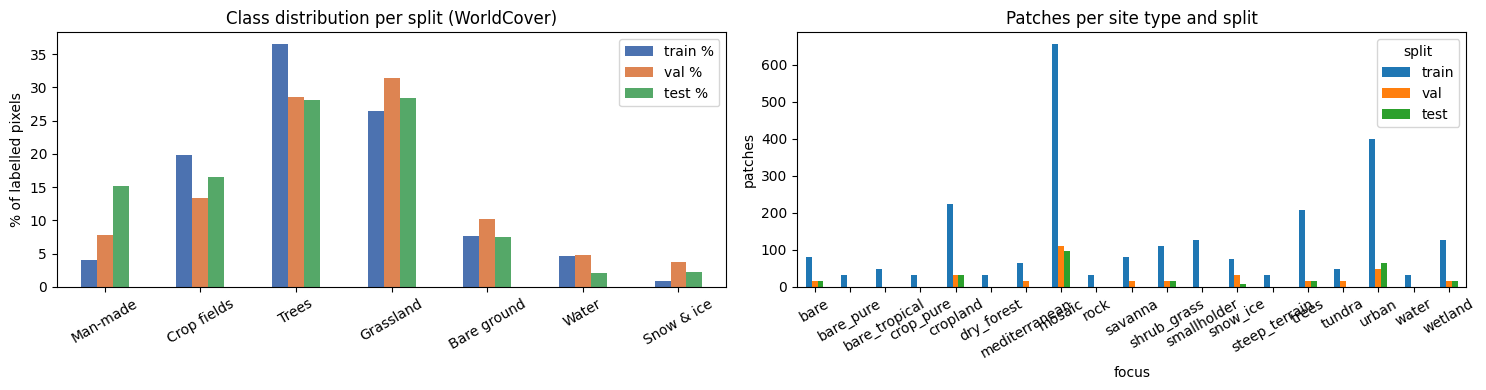

In [6]:
counts = {s: np.bincount(label_classes(Y[s])[Y[s] >= 0].ravel(), minlength=N_CLASSES) for s in SPLITS}
# the reference (2021, earlier sites) defines class weights and normalisation, as in Iter2_Test_1_Full
Y_REF = Y["train"][REF_IDX]
counts["train_ref"] = np.bincount(label_classes(Y_REF)[Y_REF >= 0].ravel(), minlength=N_CLASSES)
agree_counts = {s: np.bincount(Y[s][(Y[s] >= 0) & (Y[s] < N_CLASSES)].ravel(), minlength=N_CLASSES) for s in SPLITS}
dist = pd.DataFrame({f"{s} %": counts[s] / counts[s].sum() * 100 for s in SPLITS}, index=CLASS_NAMES)
dist["train reference %"] = counts["train_ref"] / counts["train_ref"].sum() * 100
dist["train agreement %"] = agree_counts["train"] / np.maximum(counts["train"], 1) * 100
display(dist.round(1))
for s in SPLITS:
    print(f"{s}: {agree_counts[s].sum() / counts[s].sum() * 100:.1f}% of labelled pixels are agreement pixels")

# agreement per class: WorldCover + Dynamic World (2 maps) vs the three-map vote, training windows of the reference
ref_wc = label_classes(Y["train"][REF_IDX])
ref_yv = np.stack([TILE_YV[train_window(i)[0]][train_window(i)[1]:train_window(i)[1] + PATCH,
                                               train_window(i)[2]:train_window(i)[2] + PATCH] for i in REF_IDX])
two = np.bincount(Y["train"][REF_IDX][(Y["train"][REF_IDX] >= 0) & (Y["train"][REF_IDX] < N_CLASSES)].ravel(),
                  minlength=N_CLASSES)
vote_cls = ref_yv[(ref_yv >= 0) & (ref_yv < N_CLASSES)]
three = np.bincount(vote_cls.ravel(), minlength=N_CLASSES)
total = np.bincount(ref_wc[ref_wc >= 0].ravel(), minlength=N_CLASSES)
display(pd.DataFrame({"WorldCover pixels": total, "agree, 2 maps %": two / np.maximum(total, 1) * 100,
                      "decided by the vote (pixels, % of WorldCover)": three / np.maximum(total, 1) * 100},
                     index=CLASS_NAMES).round(1))
print(f"agreement pixels: 2 maps {two.sum() / total.sum() * 100:.1f}% -> vote {three.sum() / total.sum() * 100:.1f}% "
      "(training windows of the reference)")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dist[[f"{s} %" for s in SPLITS]].plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452", "#55a868"])
axes[0].set_ylabel("% of labelled pixels")
axes[0].set_title("Class distribution per split (WorldCover)")
axes[0].tick_params(axis="x", rotation=30)
all_patches = pd.concat([index[s].assign(split=s) for s in SPLITS], ignore_index=True)
pd.crosstab(all_patches.focus, all_patches.split)[SPLITS].plot.bar(ax=axes[1])
axes[1].set_ylabel("patches")
axes[1].set_title("Patches per site type and split")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**What the radar sees** (R = VV, G = VH, B = VV - VH; explained in the 1st iteration, section 3). With terrain flattening, hillsides in mosaic tiles should no longer show a bright / dark stripe pattern that follows the relief. Black in the agreement row marks pixels where the two label maps disagree: they cluster along boundaries.

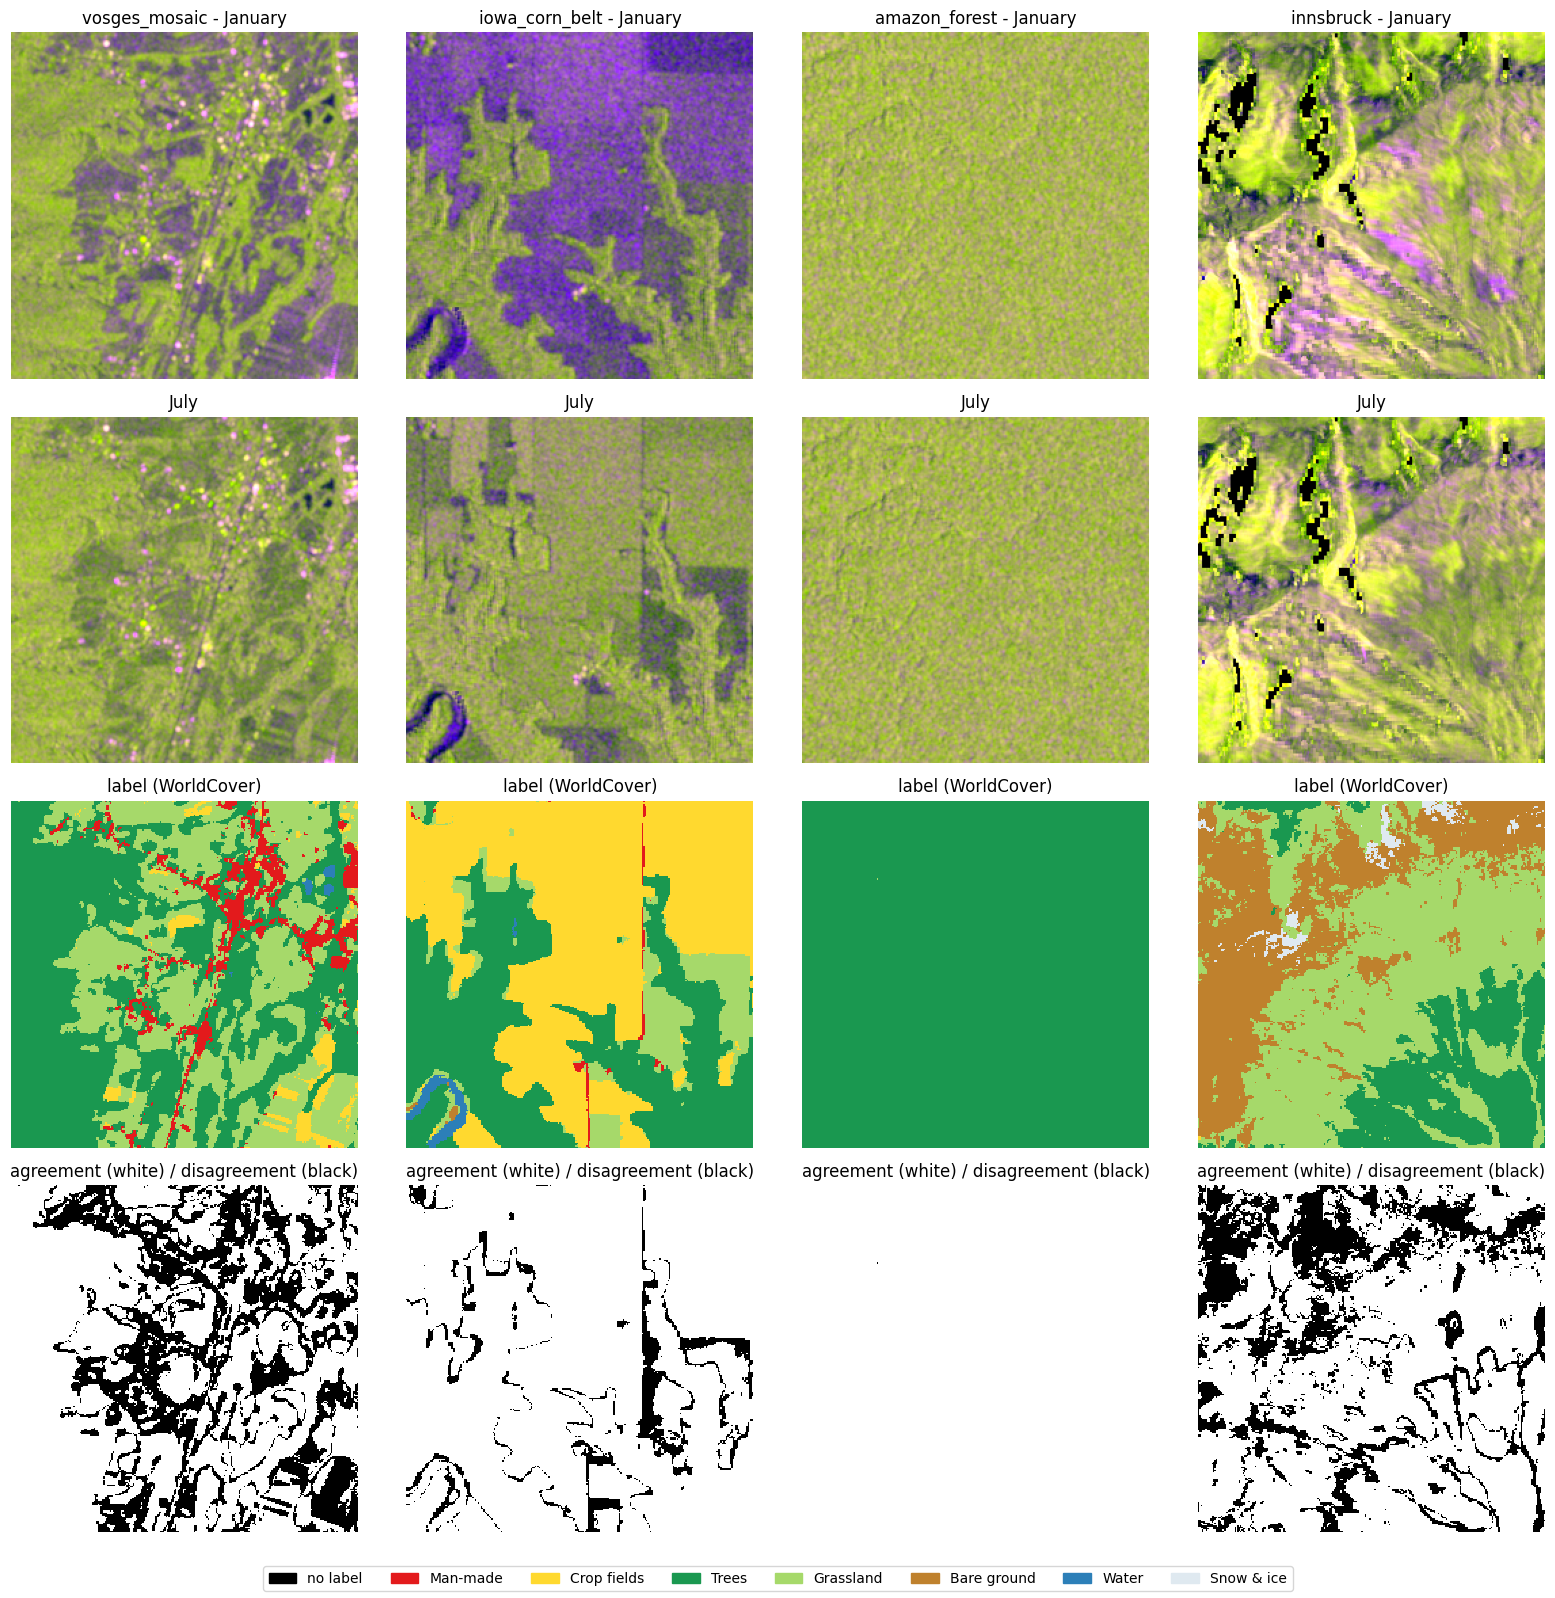

In [7]:
def false_colour(codes_2hw):
    vv, vh = DB_LUT[codes_2hw[0]], DB_LUT[codes_2hw[1]]
    rgb = np.stack([vv, vh, vv - vh], -1)
    for b, (lo, hi) in enumerate([(-20, 0), (-27, -7), (2, 15)]):
        rgb[..., b] = np.clip((rgb[..., b] - lo) / (hi - lo), 0, 1)
    return np.nan_to_num(rgb)


focus_types = [f for f in ["mosaic", "cropland", "trees", "urban"] if f in set(index["train"].focus)]
examples = [index["train"][index["train"].focus == f].index[0] for f in focus_types]
fig, axes = plt.subplots(4, len(examples), figsize=(4 * len(examples), 16), squeeze=False)
for j, i in enumerate(examples):
    x, y = train_patch(i)
    axes[0, j].imshow(false_colour(x[0]))
    axes[0, j].set_title(f"{index['train'].site[i]} - January")
    axes[1, j].imshow(false_colour(x[6]))
    axes[1, j].set_title("July")
    axes[2, j].imshow(label_classes(y) + 1, cmap=CMAP, vmin=0, vmax=N_CLASSES, interpolation="nearest")
    axes[2, j].set_title("label (WorldCover)")
    axes[3, j].imshow((y >= 0) & (y < N_CLASSES), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    axes[3, j].set_title("agreement (white) / disagreement (black)")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=LEGEND, loc="lower center", ncol=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

## 4. Input features: monthly channels and seasonal statistics

**Monthly channels** (unchanged): VV, VH and VV - VH in dB per input month, standardised with train-only statistics; missing pixels become 0 (the channel mean). The month window wraps around the year (January uses November and December).

**Seasonal statistics** (every variant). Rural land-cover classes are defined by their yearly cycle: fields are ploughed, grow and are harvested; grassland stays green; forest is stable; water is dark all year. The statistics describe that cycle **without depending on the month order**, so they work the same in both hemispheres (the reason PCA was dropped, see the 1st iteration, section 5, and `reports/literature survey_reiterate.md`):

| Channel | Meaning | Helps with |
|---|---|---|
| VV mean, VH mean, VV-VH mean | the average signal over the year | city vs forest vs field vs water |
| VV low, VH low | 2nd darkest month (robust minimum) | water (always dark), snow and frozen ground (dark in winter only) |
| VV high, VH high | 2nd brightest month (robust maximum) | crops at full growth, buildings |
| VH std | how much the vegetation signal varies over the year | cropland (strong cycle) vs trees and grassland (weak) |
| water months | share of months with VV below -18 dB | permanent water (~1) vs seasonally flooded wetland (between 0 and 1) |

A winter month that looks like water can no longer flip a forest pixel on its own: the yearly statistics still say "forest". Month dropout (section 5) teaches the model to trust them.

All statistics are standardised with train statistics and computed **once** per tile (float16).

channel mean (VV, VH, VV-VH): [ -9.705 -16.914   7.209]
channel std  (VV, VH, VV-VH): [4.515 4.857 2.546]
9 seasonal statistics precomputed in 128s (9.8 GB)


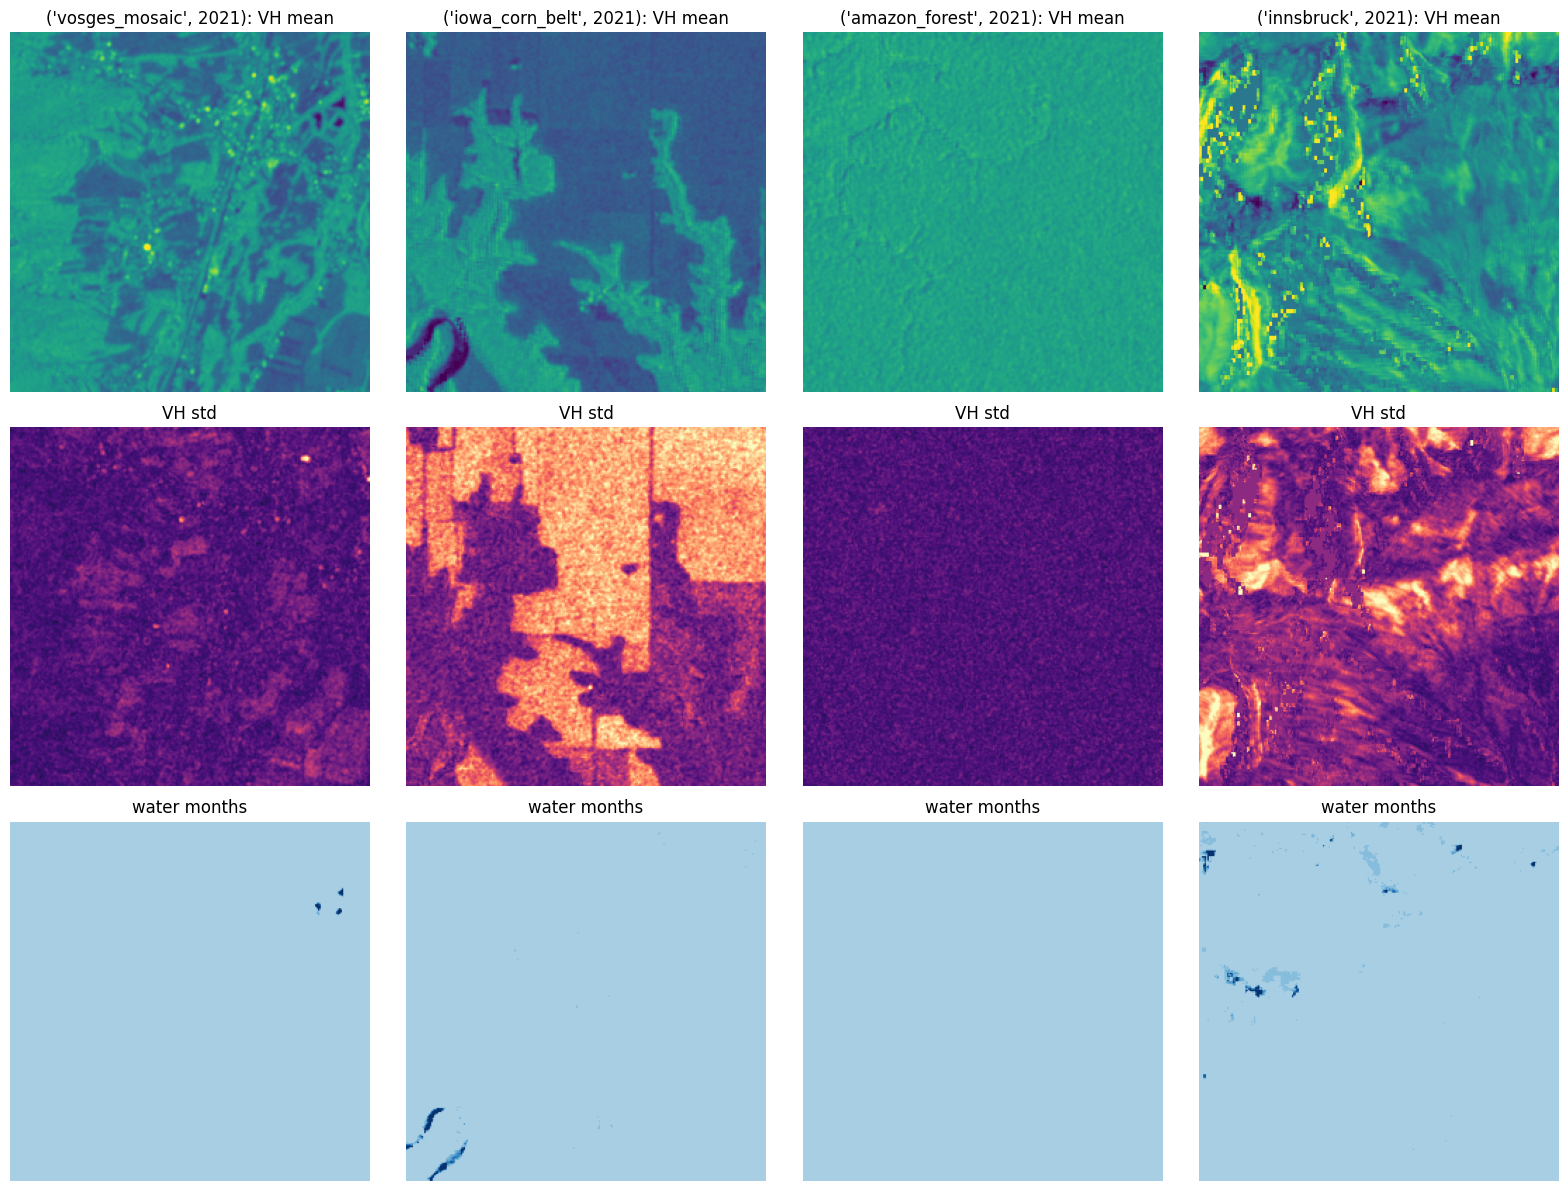

In [8]:
def standardise(f, mean, std):
    return np.nan_to_num((f - mean[None, :, None, None]) / std[None, :, None, None], nan=0.0)


def window_months(month, n_months):
    return [(month - j) % 12 for j in range(n_months - 1, -1, -1)]


def take_months(codes, months):
    """codes (12, 2, H, W) -> (len(months), 2, H, W); an empty month list gives an empty array (year_stats)."""
    return codes[months] if months else codes[:0]


# normalisation from the reference windows only, so the reference is identical to Iter2_Test_1_Full
sample = DB_LUT[np.stack([train_patch(i)[0][:, :, ::4, ::4] for i in REF_IDX[::4]])]
feats = np.stack([sample[:, :, 0], sample[:, :, 1], sample[:, :, 0] - sample[:, :, 1]], 0).reshape(3, -1)
CH_MEAN = np.nanmean(feats, axis=1).astype(np.float32)
CH_STD = np.nanstd(feats, axis=1).astype(np.float32)
del sample, feats
print("channel mean (VV, VH, VV-VH):", CH_MEAN.round(3))
print("channel std  (VV, VH, VV-VH):", CH_STD.round(3))

WATER_DB = -18.0
STAT_NAMES = ["VV mean", "VH mean", "VV-VH mean", "VV low", "VV high", "VH low", "VH high", "VH std", "water months"]
N_STATS = len(STAT_NAMES)


def stats_raw(codes):
    db = DB_LUT[codes]
    vv, vh = db[:, 0], db[:, 1]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        vv_sorted = np.sort(np.where(np.isnan(vv), np.nanmean(vv, 0), vv), 0)
        vh_sorted = np.sort(np.where(np.isnan(vh), np.nanmean(vh, 0), vh), 0)
        n_valid = np.maximum((~np.isnan(vv)).sum(0), 1)
        out = np.stack([np.nanmean(vv, 0), np.nanmean(vh, 0), np.nanmean(vv - vh, 0),
                        vv_sorted[1], vv_sorted[-2], vh_sorted[1], vh_sorted[-2],
                        np.nanstd(vh, 0), (vv < WATER_DB).sum(0) / n_valid])
    return out.astype(np.float32)


def fit_mean_std(maps):
    flat = np.concatenate([m.reshape(m.shape[0], -1) for m in maps], 1)
    return np.nanmean(flat, 1).astype(np.float32), np.nanstd(flat, 1).astype(np.float32)


STAT_MEAN, STAT_STD = fit_mean_std([stats_raw(train_patch(i)[0][:, :, ::8, ::8])
                                    for i in REF_IDX[::2]])
STAT_STD = np.maximum(STAT_STD, 1e-3)


def stats_maps(codes, rows=128):
    out = np.empty((N_STATS, *codes.shape[-2:]), dtype=np.float16)
    for r in range(0, codes.shape[-2], rows):
        out[:, r:r + rows] = standardise(stats_raw(codes[:, :, r:r + rows])[None], STAT_MEAN, STAT_STD)[0]
    return out


t0 = time.time()
STATIC_TILE = {site: stats_maps(x) for site, x in TILE_X.items()}
STATIC_X = {s: np.stack([stats_maps(x) for x in X[s]]) for s in ("val", "test")}
gb = (sum(m.nbytes for m in STATIC_TILE.values()) + sum(m.nbytes for m in STATIC_X.values())) / 1e9
print(f"{N_STATS} seasonal statistics precomputed in {time.time() - t0:.0f}s ({gb:.1f} GB)")

fig, axes = plt.subplots(3, len(examples), figsize=(4 * len(examples), 12), squeeze=False)
for j, i in enumerate(examples):
    site, r, c = train_window(i)
    s = STATIC_TILE[site][:, r:r + PATCH, c:c + PATCH].astype(np.float32)
    for row, (name, cmap) in enumerate([("VH mean", "viridis"), ("VH std", "magma"), ("water months", "Blues")]):
        axes[row, j].imshow(s[STAT_NAMES.index(name)], cmap=cmap, vmin=-2, vmax=3)
        axes[row, j].set_title(f"{site}: {name}" if row == 0 else name)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**How to read this.** *VH mean* is bright for forest and buildings, dark for water and bare soil. *VH std* is bright where vegetation changes over the year (fields) and dark for forest, cities and water. *Water months* is dark blue for permanent water and lighter for land that is flooded only in some months.

## 5. Datasets, augmentation and class balancing

Unchanged from the 1st iteration (section 6 there): one item = one patch, one random target month, the annual label; random crop position (±128 px), flips and 90° rotations, VV / VH brightness shift (±1 dB) and 0.5 dB noise; class weights `sqrt(median_freq / freq)` and a class-aware patch sampler; batches cut on the GPU when the data fits.

Changed:
- **Month dropout 0.3.** Each input month is blanked with chance `MONTH_DROP` (for `month_year` that is the whole monthly input). The model then has only the yearly statistics and must still get the class right, which is exactly what stops a dark winter month from turning forest into water.
- **No PCA or terrain channels**: the static input is the 9 seasonal statistics for every variant.
- `year_stats` has no monthly input at all (`take_months` with an empty window).
- Class weights and the patch sampler count every WorldCover pixel.
New in the 4th iteration:
- **Class weights** come from the reference windows (2021, earlier sites), as in `Iter2_Test_1_Full`, for every configuration.
- **Sampling per configuration.** `PATCH_WEIGHTS` is the class-aware weight of every training window; `config_weights(cfg)` sets it to 0 for windows of years or site groups the configuration does not use, and divides the weight of a window by the number of its years. Every configuration draws `SAMPLES_PER_EPOCH` windows per epoch, so the compute per run is the same.


In [9]:
def window_codes(codes, month, variant):
    return take_months(codes, window_months(month, variant["n_months"]))


LUT_T = torch.tensor(DB_LUT, device=DEVICE)
CH_MEAN_T = torch.tensor(CH_MEAN, device=DEVICE).view(1, 1, 3, 1, 1)
CH_STD_T = torch.tensor(CH_STD, device=DEVICE).view(1, 1, 3, 1, 1)


def gpu_input(codes, static, shift_db=None, month_drop=0.0):
    """uint8 codes (B, months, 2, H, W) + float16 statistics (B, S, H, W) -> standardised model input on the GPU.

    VV, VH, VV-VH per month (oldest first), then the seasonal statistics. shift_db (B, 2) adds the VV / VH
    brightness shift and 0.5 dB noise; month_drop blanks each month with this chance (code 0 -> 0 after
    standardisation).
    """
    static = static.to(DEVICE, non_blocking=True).float()
    if codes.shape[1] == 0:
        return static.contiguous(memory_format=torch.channels_last)
    codes = codes.to(DEVICE, non_blocking=True).long()
    if month_drop > 0:
        drop = torch.rand(codes.shape[:2], device=DEVICE) < month_drop
        codes = codes.masked_fill(drop[:, :, None, None, None], 0)
    db = LUT_T[codes]
    if shift_db is not None:
        db = db + shift_db.view(-1, 1, 2, 1, 1) + 0.5 * torch.randn_like(db)
    vv, vh = db[:, :, 0], db[:, :, 1]
    f = torch.nan_to_num((torch.stack([vv, vh, vv - vh], 2) - CH_MEAN_T) / CH_STD_T, nan=0.0).flatten(1, 2)
    return torch.cat([f, static], 1).contiguous(memory_format=torch.channels_last)


def gpu_augment(x, y):
    """Random flips and 90-degree rotations, drawn per sample."""
    for i in range(len(x)):
        dims = [d for d, flip in zip((-1, -2), torch.rand(2) < 0.5) if flip]
        xi, yi = (x[i].flip(dims), y[i].flip(dims)) if dims else (x[i], y[i])
        k = int(torch.randint(4, ()))
        x[i], y[i] = torch.rot90(xi, k, (-2, -1)), torch.rot90(yi, k, (-2, -1))
    return x, y


def input_channels(variant):
    return 3 * variant["n_months"] + N_STATS


class TrainDataset(Dataset):
    def __init__(self, variant):
        self.variant = variant

    def __len__(self):
        return len(TRAIN_ORIGINS)

    def __getitem__(self, i):
        site, r, c = train_window(i, *np.random.randint(-CROP_JITTER, CROP_JITTER + 1, 2))
        month = np.random.randint(12)
        codes = window_codes(TILE_X[site][:, :, r:r + PATCH, c:c + PATCH], month, self.variant)
        static = STATIC_TILE[site][:, r:r + PATCH, c:c + PATCH]
        label = TILE_Y[site][r:r + PATCH, c:c + PATCH].astype(np.int64)
        return torch.from_numpy(codes), torch.from_numpy(static), torch.from_numpy(label), month


class EvalDataset(Dataset):
    def __init__(self, x, y, static, variant, months=range(12)):
        self.x, self.y, self.static, self.variant = x, y, static, variant
        self.items = [(i, m) for i in range(len(x)) for m in months]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, k):
        i, month = self.items[k]
        codes = window_codes(self.x[i], month, self.variant)
        return (torch.from_numpy(codes), torch.from_numpy(self.static[i]),
                torch.from_numpy(self.y[i].astype(np.int64)), month)


def seed_worker(worker_id):
    np.random.seed(torch.initial_seed() % 2 ** 32)


def size_gb(arrays):
    return sum(a.nbytes for a in arrays) / 1e9


EVAL_SPLITS = ("val", "test")
train_gb = size_gb([*TILE_X.values(), *STATIC_TILE.values(), *TILE_Y.values()])
eval_gb = size_gb([X[s] for s in EVAL_SPLITS] + [STATIC_X[s] for s in EVAL_SPLITS] + [Y[s] for s in EVAL_SPLITS])
free_gb = 0.9 * GPU_MEM_GB - GPU_TRAIN_RESERVE_GB
EVAL_ON_GPU = DEVICE.type == "cuda" and eval_gb <= free_gb
TRAIN_ON_GPU = EVAL_ON_GPU and eval_gb + 1.5 * train_gb <= free_gb   # + vote labels
assert TRAIN_ON_GPU, "all data must fit on the GPU in this notebook (lower GPU_TRAIN_RESERVE_GB or use fewer years)"

assert DEVICE.type == "cuda", "the 5th-iteration notebook needs a GPU (labels per configuration are cut on the GPU)"
if EVAL_ON_GPU:
    X_GPU = {s: torch.from_numpy(X[s]).to(DEVICE) for s in EVAL_SPLITS}
    STATIC_GPU = {s: torch.from_numpy(STATIC_X[s]).to(DEVICE) for s in EVAL_SPLITS}
    Y_GPU = {s: torch.from_numpy(Y[s]).to(DEVICE) for s in EVAL_SPLITS}
    YV_GPU = {s: torch.from_numpy(YV[s]).to(DEVICE) for s in EVAL_SPLITS}
LABEL_SETS = {"worldcover": (Y, "Y_GPU"), "vote": (YV, "YV_GPU")}

TRAIN_SITE_ID = {site: k for k, site in enumerate(TILE_X)}
if TRAIN_ON_GPU:
    size = max(TILE_Y[site].shape[0] for site in TILE_X)
    TILE_X_GPU = torch.zeros((len(TILE_X), 12, 2, size, size), dtype=torch.uint8, device=DEVICE)
    TILE_S_GPU = torch.zeros((len(TILE_X), N_STATS, size, size), dtype=torch.float16, device=DEVICE)
    TILE_Y_GPU = torch.full((len(TILE_X), size, size), IGNORE, dtype=torch.int16, device=DEVICE)
    TILE_YV_GPU = torch.full((len(TILE_X), size, size), IGNORE, dtype=torch.int16, device=DEVICE)
    for site, k in TRAIN_SITE_ID.items():
        h, w = TILE_Y[site].shape
        TILE_X_GPU[k, :, :, :h, :w] = torch.from_numpy(TILE_X[site])
        TILE_S_GPU[k, :, :h, :w] = torch.from_numpy(STATIC_TILE[site])
        TILE_Y_GPU[k, :h, :w] = torch.from_numpy(TILE_Y[site])
        TILE_YV_GPU[k, :h, :w] = torch.from_numpy(TILE_YV[site])

print(f"data: train {train_gb:.1f} GB, val + test {eval_gb:.1f} GB | GPU space for data: {max(free_gb, 0):.1f} GB")
print("train batches:", "cut on the GPU" if TRAIN_ON_GPU else f"DataLoader, {NUM_WORKERS} workers",
      "| val/test batches:", "cut on the GPU" if EVAL_ON_GPU else f"DataLoader, {NUM_WORKERS} workers")


def gpu_train_batches(variant, steps, weights, labels="worldcover"):
    """Same sampling as TrainDataset + WeightedRandomSampler, but cut from the tiles on the GPU."""
    label_gpu = TILE_YV_GPU if labels == "vote" else TILE_Y_GPU
    ids = torch.multinomial(torch.as_tensor(weights, dtype=torch.double), steps * BATCH, replacement=True)
    for b in range(steps):
        codes, static, label_list = [], [], []
        for i in ids[b * BATCH:(b + 1) * BATCH].tolist():
            site, r, c = train_window(i, *np.random.randint(-CROP_JITTER, CROP_JITTER + 1, 2))
            k = TRAIN_SITE_ID[site]
            months = window_months(np.random.randint(12), variant["n_months"])
            codes.append(take_months(TILE_X_GPU[k, :, :, r:r + PATCH, c:c + PATCH], months))
            static.append(TILE_S_GPU[k, :, r:r + PATCH, c:c + PATCH])
            label_list.append(label_gpu[k, r:r + PATCH, c:c + PATCH])
        yield torch.stack(codes), torch.stack(static), torch.stack(label_list).long()


def eval_batches(split, variant, months=range(12), ids=None, labels="worldcover"):
    """Fixed val/test patches, each with every month in `months`: (codes, static, label, month) batches."""
    y_gpu = YV_GPU if labels == "vote" else Y_GPU
    ids = range(len(X[split])) if ids is None else [int(i) for i in ids]
    if not EVAL_ON_GPU:
        sel = slice(None) if isinstance(ids, range) else ids
        ds = EvalDataset(X[split][sel], Y[split][sel], STATIC_X[split][sel], variant, months)
        yield from DataLoader(ds, 2 * BATCH, num_workers=NUM_WORKERS, pin_memory=True)
        return
    items = [(i, m) for i in ids for m in months]
    for b in range(0, len(items), 2 * BATCH):
        chunk = items[b:b + 2 * BATCH]
        codes = torch.stack([take_months(X_GPU[split][i], window_months(m, variant["n_months"])) for i, m in chunk])
        static = torch.stack([STATIC_GPU[split][i] for i, _ in chunk])
        label_batch = torch.stack([y_gpu[split][i] for i, _ in chunk]).long()
        yield codes, static, label_batch, torch.tensor([m for _, m in chunk], device=DEVICE)


freq = counts["train_ref"] / counts["train_ref"].sum()
CLASS_WEIGHTS = np.sqrt(np.median(freq) / np.clip(freq, 1e-6, None))
CLASS_WEIGHTS = (CLASS_WEIGHTS / CLASS_WEIGHTS.mean()).astype(np.float32)
display(pd.DataFrame({"train share %": (freq * 100).round(2), "loss weight": CLASS_WEIGHTS.round(2)},
                     index=CLASS_NAMES))

patch_classes = label_classes(Y["train"])
patch_frac = np.stack([np.bincount(t[t >= 0], minlength=N_CLASSES) / max((t >= 0).sum(), 1) for t in patch_classes])
PATCH_WEIGHTS = np.where(patch_frac >= 0.01, CLASS_WEIGHTS[None], 0).max(1)
print("patch sampling weight range:", PATCH_WEIGHTS.min().round(2), "-", PATCH_WEIGHTS.max().round(2))


WINDOW_KEY = (train_all.site + "_" + train_all.row.astype(str) + "_" + train_all.col.astype(str)).to_numpy()


def config_weights(cfg):
    """Sampling weight of every training window for one configuration (0 = not used).

    A window that exists in several years is one place seen in several years: its weight is shared between
    its years, so the class balance stays that of the reference and the later years add variety, not weight.
    """
    use = np.isin(ORIGIN_YEAR, cfg["years"]) & ((ORIGIN_ITER == 2) | cfg["new_sites"])
    n_years = pd.Series(use.astype(int)).groupby(WINDOW_KEY).transform("sum").to_numpy()
    return np.where(use, PATCH_WEIGHTS / np.maximum(n_years, 1), 0.0)


def class_shares(weights):
    """Expected share of each class among the drawn pixels for a set of window weights, in %."""
    p = weights / weights.sum()
    return (p @ patch_frac) * 100


for name, cfg in CONFIGS.items():
    w = config_weights(cfg)
    print(f"{name:22} draws from {(w > 0).sum():5} training windows")
print("expected class share of the drawn pixels (%), per configuration:")
display(pd.DataFrame({name: class_shares(config_weights(cfg)) for name, cfg in CONFIGS.items()},
                     index=CLASS_NAMES).round(1))


data: train 22.1 GB, val + test 1.7 GB | GPU space for data: 79.8 GB
train batches: cut on the GPU | val/test batches: cut on the GPU


,train share %,loss weight
Man-made,9.04,0.99
Crop fields,16.05,0.74
Trees,34.11,0.51
Grassland,25.32,0.59
Bare ground,7.34,1.10
Water,5.36,1.29
Snow & ice,2.79,1.78


patch sampling weight range: 0.51 - 1.78
V0_worldcover          draws from  2234 training windows
V1_vote                draws from  2234 training windows
V2_vote_all_data       draws from  7588 training windows
expected class share of the drawn pixels (%), per configuration:


,V0_worldcover,V1_vote,V2_vote_all_data
Man-made,10.1,10.1,9.4
Crop fields,15.6,15.6,16.5
Trees,29.7,29.7,29.1
Grassland,23.5,23.5,23.1
Bare ground,8.9,8.9,10.8
Water,7.0,7.0,6.5
Snow & ice,5.1,5.1,4.6


## 6. The model

The U-Net of the 2nd iteration with an exchangeable encoder (explained in `3rd_iteration_encoders.ipynb`, section 6). With `ENCODER = "resnet34"` it is exactly the model of `Iter2_Test_1_Full`.

In [10]:
class UpBlock(nn.Module):
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([x, skip], 1)
        return self.conv(x)


def adapt_first_conv(conv, in_ch):
    """The ImageNet first layer for in_ch inputs: mean of the RGB filters, scaled by 3 / in_ch (as before)."""
    new = nn.Conv2d(in_ch, conv.out_channels, conv.kernel_size, conv.stride, conv.padding, bias=conv.bias is not None)
    with torch.no_grad():
        new.weight.copy_(conv.weight.mean(1, keepdim=True).repeat(1, in_ch, 1, 1) * 3 / in_ch)
        if conv.bias is not None:
            new.bias.copy_(conv.bias)
    return new


# Channels of the 5 encoder outputs s0 (1/2 resolution) ... s4 (1/32)
ENCODER_CHANNELS = {
    "resnet34": (64, 64, 128, 256, 512),
    "resnet50": (64, 256, 512, 1024, 2048),
    "vgg16_bn": (128, 256, 512, 512, 512),
    "densenet121": (64, 256, 512, 1024, 1024),
    "efficientnet_b0": (16, 24, 40, 112, 320),
}


def build_encoder(name, in_ch, pretrained):
    """torchvision classifier -> (stem, pool, [enc1, enc2, enc3, enc4]). stem.0 is always the first convolution."""
    try:
        net = getattr(torchvision.models, name)(weights="DEFAULT" if pretrained else None)
    except Exception as err:
        print("pretrained weights unavailable, using random init:", err)
        net = getattr(torchvision.models, name)(weights=None)
    if name.startswith("resnet"):
        stem = nn.Sequential(adapt_first_conv(net.conv1, in_ch), net.bn1, net.relu)
        return stem, net.maxpool, [net.layer1, net.layer2, net.layer3, net.layer4]
    if name == "vgg16_bn":
        f = net.features   # 5 blocks of 3x3 conv + BN + ReLU, max pool after each (indices 6, 13, 23, 33, 43)
        stem = nn.Sequential(adapt_first_conv(f[0], in_ch), *f[1:13])
        return stem, nn.Identity(), [f[13:23], f[23:33], f[33:43], f[43:44]]
    if name == "densenet121":
        f = net.features
        stem = nn.Sequential(adapt_first_conv(f.conv0, in_ch), f.norm0, f.relu0)
        return stem, f.pool0, [f.denseblock1, nn.Sequential(f.transition1, f.denseblock2),
                               nn.Sequential(f.transition2, f.denseblock3),
                               nn.Sequential(f.transition3, f.denseblock4, f.norm5, nn.ReLU(inplace=True))]
    if name == "efficientnet_b0":
        f = net.features   # f[8], the 1x1 convolution to 1280 channels for the classifier, is not used
        stem = nn.Sequential(adapt_first_conv(f[0][0], in_ch), f[0][1], f[0][2], f[1])
        return stem, nn.Identity(), [f[2], f[3], nn.Sequential(f[4], f[5]), nn.Sequential(f[6], f[7])]
    raise ValueError(f"unknown encoder {name}; choose one of {list(ENCODER_CHANNELS)}")


class UNet(nn.Module):
    """U-Net with an exchangeable encoder. With resnet34 the layers and their names are identical to the
    UNetResNet34 of the 2nd iteration, so its weights load unchanged."""

    def __init__(self, in_ch, n_classes, encoder="resnet34", pretrained=True):
        super().__init__()
        ch = ENCODER_CHANNELS[encoder]
        self.stem, self.pool, (self.enc1, self.enc2, self.enc3, self.enc4) = build_encoder(encoder, in_ch, pretrained)
        self.dec4 = UpBlock(ch[4], ch[3], 256)
        self.dec3 = UpBlock(256, ch[2], 128)
        self.dec2 = UpBlock(128, ch[1], 64)
        self.dec1 = UpBlock(64, ch[0], 64)
        self.dec0 = UpBlock(64, 0, 32)
        self.dropout = nn.Dropout2d(DROPOUT)
        self.head = nn.Conv2d(32, n_classes, 1)

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.enc1(self.pool(s0))
        s2 = self.enc2(s1)
        s3 = self.enc3(s2)
        s4 = self.enc4(s3)
        d = self.dec4(s4, s3)
        d = self.dec3(d, s2)
        d = self.dec2(d, s1)
        d = self.dec1(d, s0)
        d = self.dec0(d)
        return self.head(self.dropout(d))


def n_params(model):
    return sum(p.numel() for p in model.parameters())


# Shape check of every encoder in this notebook (random weights, nothing is downloaded)
PARAMS_M = {}
for enc in dict.fromkeys(cfg["encoder"] for cfg in CONFIGS.values()):
    m = UNet(input_channels(VARIANT), N_CLASSES, enc, pretrained=False).eval()
    with torch.no_grad():
        out = m(torch.zeros(1, input_channels(VARIANT), PATCH, PATCH))
    PARAMS_M[enc] = n_params(m) / 1e6
    print(f"{enc:16} {PARAMS_M[enc]:5.1f} M parameters | output {tuple(out.shape)}")
    del m

resnet34          24.6 M parameters | output (1, 7, 256, 256)


## 7. Loss and metrics

**Loss = weighted cross-entropy on every WorldCover pixel + 0.5 × Lovász-softmax on agreement pixels**

| Part | Pixels | Why |
|---|---|---|
| cross-entropy (class weights, label smoothing 0.1) | all WorldCover pixels; agreement pixels weight 1, disagreement pixels `DISAGREE_WEIGHT` = 0.5 | boundaries (forest edges, field edges, roads, streams) are mostly disagreement pixels. The 1st iteration ignored them, so the model never learned where an edge is. Weight 0.5 still trains them, but trusts them less, because there one of the two maps is wrong |
| Lovász-softmax (1st iteration, section 8) | agreement pixels only | it optimises IoU directly; on uncertain pixels it would chase label noise |

The **logged loss** stays the plain weighted cross-entropy on agreement pixels, so the curves read the same as in the 1st iteration.

**Metrics.** OA, IoU, mIoU and F1 as before. Every score is computed twice:
- on **agreement pixels** (main score; the same pixels the 1st iteration was scored on);
- on **all WorldCover pixels** (`_all`), which includes boundaries. Lower, because one of the two maps is wrong on many of these pixels, but it shows whether edges improve.

**Changed by the experiments of this notebook:** `lovasz_weight` (T2: 0 = cross-entropy only). The optimiser (T1) is set in section 8.

In [11]:
def lovasz_grad(fg_sorted):
    total = fg_sorted.sum()
    intersection = total - fg_sorted.cumsum(0)
    union = total + (1 - fg_sorted).cumsum(0)
    jaccard = 1 - intersection / union
    jaccard[1:] = jaccard[1:] - jaccard[:-1]
    return jaccard


def lovasz_softmax(probs, target, sample=1.0):
    probs = probs.permute(0, 2, 3, 1).reshape(-1, probs.shape[1])
    target = target.reshape(-1)
    valid = (target != IGNORE) & (torch.rand(len(target), device=target.device) < sample)
    probs, target = probs[valid], target[valid]
    losses = []
    for c in range(probs.shape[1]):
        fg = (target == c).float()
        if fg.sum() == 0:
            continue
        errors, order = (fg - probs[:, c]).abs().sort(descending=True)
        losses.append(torch.dot(errors, lovasz_grad(fg[order])))
    return torch.stack(losses).mean() if losses else probs.sum() * 0


class WorldCoverLoss(nn.Module):
    def __init__(self, class_weights, disagree_weight=0.5, label_smoothing=0.1, lovasz_weight=0.5, bootstrap_beta=1.0):
        super().__init__()
        self.w = class_weights
        self.disagree_weight, self.label_smoothing = disagree_weight, label_smoothing
        self.lovasz_weight, self.bootstrap_beta = lovasz_weight, bootstrap_beta

    def agree_ce(self, logits, y):
        """Plain weighted cross-entropy on agreement pixels: the logged loss."""
        target, agree = split_label(y)
        return F.cross_entropy(logits.float(), target.masked_fill(~agree, IGNORE), weight=self.w, ignore_index=IGNORE)

    def forward(self, logits, y):
        """Returns (total loss to optimise, logged cross-entropy)."""
        logits = logits.float()
        target, agree = split_label(y)
        pixel_w = (target != IGNORE).float() * (self.disagree_weight + (1 - self.disagree_weight) * agree.float())
        if self.bootstrap_beta < 1:
            # soft bootstrapping (Reed et al. 2015): the target is beta x label + (1 - beta) x the model's own prediction
            soft = F.one_hot(target.clamp(min=0), N_CLASSES).permute(0, 3, 1, 2).float()
            soft = soft * (1 - self.label_smoothing) + self.label_smoothing / N_CLASSES
            soft = self.bootstrap_beta * soft + (1 - self.bootstrap_beta) * logits.softmax(1).detach()
            ce = F.cross_entropy(logits, soft, weight=self.w, reduction="none")
        else:
            ce = F.cross_entropy(logits, target, weight=self.w, ignore_index=IGNORE, reduction="none",
                                 label_smoothing=self.label_smoothing)
        ce = (ce * pixel_w).sum() / (self.w[target.clamp(min=0)] * pixel_w).sum().clamp(min=1e-6)
        target_agree = target.masked_fill(~agree, IGNORE)
        total = ce
        if self.lovasz_weight > 0:
            total = total + self.lovasz_weight * lovasz_softmax(logits.softmax(1), target_agree, LOVASZ_SAMPLE)
        logged = F.cross_entropy(logits, target_agree, weight=self.w, ignore_index=IGNORE)
        return total, logged.detach()


def update_confusion(conf, pred, target):
    valid = target != IGNORE
    conf += torch.bincount(target[valid] * N_CLASSES + pred[valid],
                           minlength=N_CLASSES ** 2).reshape(N_CLASSES, N_CLASSES)
    return conf


def metrics_from_confusion(conf):
    conf = conf.double()
    tp = conf.diag()
    fp, fn = conf.sum(0) - tp, conf.sum(1) - tp
    iou = tp / (tp + fp + fn).clamp(min=1)
    f1 = 2 * tp / (2 * tp + fp + fn).clamp(min=1)
    present = conf.sum(1) > 0
    return {"OA": (tp.sum() / conf.sum().clamp(min=1)).item(),
            "mIoU": iou[present].mean().item(),
            "IoU": iou.cpu().numpy(), "F1": f1.cpu().numpy(),
            "precision": (tp / (tp + fp).clamp(min=1)).cpu().numpy(),
            "recall": (tp / (tp + fn).clamp(min=1)).cpu().numpy()}


CLASS_WEIGHTS_T = torch.tensor(CLASS_WEIGHTS, device=DEVICE)
criterion = WorldCoverLoss(CLASS_WEIGHTS_T)   # only its agree_ce is used, for the logged val loss

## 8. Training: all experiments

Each run is trained exactly like `Iter2_Test_1_Full` (AdamW unless the experiment says SGD, mixed precision, warmup + cosine schedule, EMA weights, early stopping on val mIoU), with its own seed. After training, each run is tested on all 12 months of the test patches (rural sites = main score; all sites) with the functions of the 2nd iteration (section 9.2 there). Then the model is freed, so only one model is on the GPU at a time.

Log line per epoch as in the 2nd iteration; after each run one summary line `--> run: val ... | rural test ... | flicker ...`. `nan` in odd epochs is normal (validation every 2nd epoch).

In [12]:
def evaluate(model, batches):
    """Scores on agreement pixels (main) and on all WorldCover pixels (_all), one prediction per (patch, month)."""
    model.eval()
    conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
    conf_all = torch.zeros_like(conf)
    loss_sum, n = 0.0, 0
    with torch.no_grad(), torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        for codes, static, yb, _ in batches:
            xb, yb = gpu_input(codes, static), yb.to(DEVICE, non_blocking=True)
            logits = model(xb)
            loss_sum += criterion.agree_ce(logits, yb).item() * len(xb)
            n += len(xb)
            pred = logits.argmax(1)
            target, agree = split_label(yb)
            update_confusion(conf, pred, target.masked_fill(~agree, IGNORE))
            update_confusion(conf_all, pred, target)
    out = metrics_from_confusion(conf)
    out["mIoU_all"] = metrics_from_confusion(conf_all)["mIoU"]
    out["loss"], out["confusion"] = loss_sum / n, conf.cpu().numpy()
    return out


def train_run(run, cfg, seed):
    """Trains one configuration with one seed; returns the EMA model with the best val mIoU and its history."""
    print(f"=== {run}: {cfg['encoder']}{'' if cfg['pretrained'] else ' (no pretraining)'}, {cfg['optimizer']}, "
          f"lr {cfg['lr']}, Lovasz {cfg['lovasz_weight']}, disagree {cfg['disagree_weight']}, "
          f"smoothing {cfg['label_smoothing']}, bootstrap {cfg['bootstrap_beta']}, seed {seed} ===")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    loss_fn = WorldCoverLoss(CLASS_WEIGHTS_T, cfg["disagree_weight"], cfg["label_smoothing"],
                             cfg["lovasz_weight"], cfg["bootstrap_beta"])
    steps = SAMPLES_PER_EPOCH // BATCH
    if not TRAIN_ON_GPU:
        sampler = WeightedRandomSampler(torch.as_tensor(config_weights(cfg), dtype=torch.double),
                                        num_samples=SAMPLES_PER_EPOCH, replacement=True)
        train_dl = DataLoader(TrainDataset(VARIANT), BATCH, sampler=sampler, num_workers=NUM_WORKERS,
                              pin_memory=True, drop_last=True, persistent_workers=NUM_WORKERS > 0,
                              worker_init_fn=seed_worker)

    model = UNet(input_channels(VARIANT), N_CLASSES, cfg["encoder"], cfg["pretrained"]).to(
        DEVICE, memory_format=torch.channels_last)
    ema = torch.optim.swa_utils.AveragedModel(
        model, multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(EMA_DECAY), use_buffers=True)
    groups = [{"params": [p for p in model.parameters() if p.ndim > 1], "weight_decay": cfg["weight_decay"]},
              {"params": [p for p in model.parameters() if p.ndim <= 1], "weight_decay": 0.0}]
    if cfg["optimizer"] == "sgd":
        optimizer = torch.optim.SGD(groups, lr=cfg["lr"], momentum=0.9, nesterov=True)
    else:
        optimizer = torch.optim.AdamW(groups, lr=cfg["lr"])
    warmup, total = WARMUP_EPOCHS * steps, MAX_EPOCHS * steps

    def lr_factor(step):
        if step < warmup:
            return (step + 1) / warmup
        return 0.5 * (1 + math.cos(math.pi * min(step - warmup, total - warmup) / (total - warmup)))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    scaler = torch.amp.GradScaler(enabled=USE_SCALER)

    history, best, best_state, wait, train_seconds = [], -1.0, None, 0, 0.0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        t0, loss_sum, n = time.time(), 0.0, 0
        conf = torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
        batches = (gpu_train_batches(VARIANT, steps, config_weights(cfg), cfg["labels"]) if TRAIN_ON_GPU
                   else ((codes, static, yb) for codes, static, yb, _ in train_dl))
        for codes, static, yb in batches:
            yb = yb.to(DEVICE, non_blocking=True)
            xb = gpu_input(codes, static, shift_db=torch.empty(len(yb), 2, device=DEVICE).uniform_(-1, 1),
                           month_drop=MONTH_DROP)
            xb, yb = gpu_augment(xb, yb)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                logits = model(xb)
                loss, ce = loss_fn(logits, yb)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            ema.update_parameters(model)
            loss_sum += ce.item() * len(xb)
            n += len(xb)
            target, agree = split_label(yb)
            update_confusion(conf, logits.detach().argmax(1), target.masked_fill(~agree, IGNORE))
        train_seconds += time.time() - t0
        train_m = metrics_from_confusion(conf)
        validate = epoch % VAL_EVERY == 0 or epoch == MAX_EPOCHS
        val_m = (evaluate(ema.module, eval_batches("val", VARIANT, VAL_MONTHS, labels=cfg["labels"])) if validate
                 else {"loss": np.nan, "OA": np.nan, "mIoU": np.nan, "mIoU_all": np.nan})
        history.append({"epoch": epoch, "train_loss": loss_sum / n, "val_loss": val_m["loss"],
                        "train_OA": train_m["OA"], "val_OA": val_m["OA"],
                        "train_mIoU": train_m["mIoU"], "val_mIoU": val_m["mIoU"], "val_mIoU_all": val_m["mIoU_all"],
                        "lr": optimizer.param_groups[0]["lr"]})
        improved = validate and val_m["mIoU"] > best
        if improved:
            best, wait = val_m["mIoU"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in ema.module.state_dict().items()}
            torch.save(best_state, RUNS_DIR / f"{run}.pt")
        elif validate:
            wait += VAL_EVERY
        print(f"epoch {epoch:2d} | train loss {loss_sum / n:.3f} mIoU {train_m['mIoU']:.3f} | "
              f"val loss {val_m['loss']:.3f} OA {val_m['OA']:.3f} mIoU {val_m['mIoU']:.3f} all {val_m['mIoU_all']:.3f} | "
              f"lr {optimizer.param_groups[0]['lr']:.1e} | {time.time() - t0:.0f}s{' *' if improved else ''}", flush=True)
        if wait >= PATIENCE:
            print(f"early stopping: no val mIoU improvement for {PATIENCE} epochs")
            break

    model.load_state_dict(best_state)
    history = pd.DataFrame(history)
    history.to_csv(RUNS_DIR / f"{run}_history.csv", index=False)
    print(f"best val mIoU {best:.3f}, weights saved to {RUNS_DIR / f'{run}.pt'}")
    return model.eval(), history, train_seconds / len(history)

In [13]:
def predict_year(model, split, variant, ids):
    """Softmax for all 12 months of the given patches: (len(ids), 12, classes, H, W) on the device."""
    batches = list(eval_batches(split, variant, range(12), ids))
    codes = torch.cat([b[0] for b in batches])
    static = torch.cat([b[1] for b in batches])
    with torch.no_grad(), torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        logits = model(gpu_input(codes, static))
    return logits.float().softmax(1).view(len(ids), 12, N_CLASSES, *logits.shape[-2:])


def smooth_months(probs):
    """Mean probability of months t-1, t, t+1 (wrapping around the year)."""
    return (probs.roll(1, 1) + probs + probs.roll(-1, 1)) / 3


def evaluate_year(model, split, variant, ids=None, labels="worldcover"):
    """12-month scores on one label set; 'tol' = tolerant (correct if the prediction matches any of the 3 maps)."""
    model.eval()
    y_src = YV if labels == "vote" else Y
    ids = list(range(len(X[split]))) if ids is None else [int(i) for i in ids]
    chunk_size = max(1, 2 * BATCH // 12)
    conf = {k: torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
            for k in ("raw", "smooth", "raw_all", "smooth_all", "tol")}
    month_conf = torch.zeros(12, N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE)
    flicker = {"raw": 0.0, "smooth": 0.0}
    for b in range(0, len(ids), chunk_size):
        chunk = ids[b:b + chunk_size]
        probs = predict_year(model, split, variant, chunk)
        y = torch.as_tensor(y_src[split][chunk], device=DEVICE).long()[:, None].expand(-1, 12, -1, -1)
        maps = torch.as_tensor(MAPS[split][chunk], device=DEVICE).long()[:, None].expand(-1, 12, -1, -1, -1)
        target, agree = split_label(y)
        target_agree = target.masked_fill(~agree, IGNORE)
        for key, p in (("raw", probs), ("smooth", smooth_months(probs))):
            pred = p.argmax(2)
            update_confusion(conf[key], pred, target_agree)
            update_confusion(conf[f"{key}_all"], pred, target)
            flicker[key] += (pred[:, 1:] != pred[:, :-1]).float().mean().item() * len(chunk)
            if key == "raw":
                for m in range(12):
                    update_confusion(month_conf[m], pred[:, m], target_agree[:, m])
                # tolerant: where WorldCover has a class, a prediction matching any map counts as that class
                hit = ((maps == (pred + 1)[:, :, None]) & (maps > 0)).any(2)
                wc = maps[:, :, 0] - 1
                tol_target = torch.where(hit, pred, wc).masked_fill(wc < 0, IGNORE)
                update_confusion(conf["tol"], pred, tol_target)
    out = {k: metrics_from_confusion(c) for k, c in conf.items()}
    out["flicker"] = {k: v / len(ids) for k, v in flicker.items()}
    out["month_mIoU"] = [metrics_from_confusion(month_conf[m])["mIoU"] for m in range(12)]
    out["confusion"] = conf["raw"].cpu().numpy()
    return out


RURAL_IDS = index["test"].index[index["test"].focus != "urban"].to_numpy()
print(f"test: {len(X['test'])} patches, {len(RURAL_IDS)} of them on rural sites (main score)")

test: 265 patches, 201 of them on rural sites (main score)


In [14]:
RUN_START = time.time()
records, histories = [], {}
for name, cfg in CONFIGS.items():
    for seed in SEEDS:
        run = f"{name}_s{seed}"
        t0 = time.time()
        model, histories[run], sec_per_epoch = train_run(run, cfg, seed)
        minutes = (time.time() - t0) / 60
        rural = evaluate_year(model, "test", VARIANT, RURAL_IDS)
        rural_vote = evaluate_year(model, "test", VARIANT, RURAL_IDS, labels="vote")
        all_sites = evaluate_year(model, "test", VARIANT)
        val_wc = evaluate(model, eval_batches("val", VARIANT, VAL_MONTHS))
        val_vote = evaluate(model, eval_batches("val", VARIANT, VAL_MONTHS, labels="vote"))
        h = histories[run]
        best_row = h.loc[h.val_mIoU.idxmax()]
        records.append({"experiment": name, "seed": seed, "run": run, "encoder": cfg["encoder"],
                        "parameters M": round(PARAMS_M.get(cfg["encoder"], n_params(model) / 1e6), 1),
                        "epochs": len(h), "best epoch": int(best_row.epoch), "minutes": round(minutes, 1),
                        "s per epoch": round(sec_per_epoch, 1),
                        "labels": cfg["labels"],
                        "val mIoU": best_row.val_mIoU, "val mIoU all": best_row.val_mIoU_all,
                        "val worldcover mIoU": val_wc["mIoU"], "val vote mIoU": val_vote["mIoU"],
                        "rural vote mIoU": rural_vote["raw"]["mIoU"], "rural tolerant mIoU": rural["tol"]["mIoU"],
                        "rural tolerant OA": rural["tol"]["OA"],
                        "train-val gap": best_row.train_mIoU - best_row.val_mIoU,
                        "rural mIoU": rural["raw"]["mIoU"], "rural mIoU smoothed": rural["smooth"]["mIoU"],
                        "rural mIoU all": rural["raw_all"]["mIoU"], "test mIoU all sites": all_sites["raw"]["mIoU"],
                        "flicker %": rural["flicker"]["raw"] * 100, "flicker smoothed %": rural["flicker"]["smooth"] * 100,
                        **{f"IoU {c}": v for c, v in zip(CLASS_NAMES, rural["raw"]["IoU"])},
                        **{f"vote IoU {c}": v for c, v in zip(CLASS_NAMES, rural_vote["raw"]["IoU"])}})
        # saved after every run, so an interrupted notebook keeps the finished runs
        pd.DataFrame(records).to_csv(OUT / "runs.csv", index=False)
        print(f"--> {run}: val vote {val_vote['mIoU']:.3f} worldcover {val_wc['mIoU']:.3f} | rural vote "
              f"{rural_vote['raw']['mIoU']:.3f} tolerant {rural['tol']['mIoU']:.3f} | worldcover rural test {rural['raw']['mIoU']:.3f} "
              f"(smoothed {rural['smooth']['mIoU']:.3f}) | flicker {rural['flicker']['raw'] * 100:.1f} % | "
              f"{minutes:.1f} min | total {(time.time() - RUN_START) / 60:.0f} min", flush=True)
        del model
        torch.cuda.empty_cache()

runs = pd.DataFrame(records)
json.dump({"total_minutes": round((time.time() - RUN_START) / 60, 1)}, open(OUT / "timing.json", "w"), indent=2)

=== V0_worldcover_s42: resnet34, adamw, lr 0.0006, Lovasz 0.5, disagree 0.5, smoothing 0.1, bootstrap 1.0, seed 42 ===
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /home/jovyan/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 116MB/s]


epoch  1 | train loss 1.308 mIoU 0.422 | val loss nan OA nan mIoU nan all nan | lr 6.0e-04 | 11s
epoch  2 | train loss 0.896 mIoU 0.656 | val loss 1.916 OA 0.096 mIoU 0.014 all 0.015 | lr 6.0e-04 | 16s *
epoch  3 | train loss 0.749 mIoU 0.701 | val loss nan OA nan mIoU nan all nan | lr 6.0e-04 | 3s
epoch  4 | train loss 0.706 mIoU 0.687 | val loss 1.522 OA 0.735 mIoU 0.560 all 0.465 | lr 5.9e-04 | 6s *
epoch  5 | train loss 0.569 mIoU 0.760 | val loss nan OA nan mIoU nan all nan | lr 5.8e-04 | 3s
epoch  6 | train loss 0.538 mIoU 0.764 | val loss 1.068 OA 0.762 mIoU 0.601 all 0.491 | lr 5.8e-04 | 5s *
epoch  7 | train loss 0.477 mIoU 0.800 | val loss nan OA nan mIoU nan all nan | lr 5.7e-04 | 3s
epoch  8 | train loss 0.496 mIoU 0.775 | val loss 0.808 OA 0.788 mIoU 0.676 all 0.545 | lr 5.5e-04 | 6s *
epoch  9 | train loss 0.464 mIoU 0.790 | val loss nan OA nan mIoU nan all nan | lr 5.4e-04 | 3s
epoch 10 | train loss 0.409 mIoU 0.823 | val loss 0.684 OA 0.808 mIoU 0.709 all 0.579 | lr 5.2

## 9. Results

### 9.1 Comparison of all configurations

Mean over the seeds. Columns:
- **val vote mIoU** decides (every configuration on the same vote labels); **val worldcover mIoU** for comparison;
- **rural vote mIoU**: rural test sites on the vote labels (the best available reference);
- **rural mIoU**: rural test sites on the WorldCover labels (comparable with all earlier iterations);
- **rural tolerant mIoU / OA**: a prediction counts if it matches any of the three maps;
- **rural mIoU all**, flicker, spread, cost as before.


4th iteration (WorldCover labels): Y0 val 0.735, rural 0.663; Y3 rural 0.659 (Crop 0.696, Grassland 0.681)
mean over 2 seeds; spread = best seed - worst seed. Decision: mean val mIoU (rural test only reported); a change counts only if it beats V0_worldcover by more than 0.02.


,val vote mIoU,val worldcover mIoU,rural vote mIoU,rural mIoU,rural tolerant mIoU,rural tolerant OA,rural mIoU smoothed,rural mIoU all,test mIoU all sites,flicker %,flicker smoothed %,val spread,rural spread,parameters M,s per epoch,epochs,train-val gap,val vs reference,rural vs reference,beats reference
experiment,,,,,,,,,,,,,,,,,,,,
V0_worldcover,0.638,0.723,0.520,0.651,0.689,0.877,0.651,0.551,0.740,1.968,0.765,0.008,0.016,24.6,2.90,26.0,0.117,0.000,0.000,False
V1_vote,0.695,0.735,0.573,0.661,0.758,0.899,0.662,0.537,0.739,2.375,0.956,0.006,0.029,24.6,2.75,34.0,0.100,0.057,0.053,True
V2_vote_all_data,0.684,0.736,0.566,0.654,0.716,0.896,0.655,0.502,0.709,2.350,0.964,0.019,0.012,24.6,2.75,29.0,0.084,0.046,0.046,True


rural test IoU per class (raw maps, agreement pixels, mean over seeds):


experiment,V0_worldcover,V1_vote,V2_vote_all_data
Man-made,0.663,0.718,0.766
Crop fields,0.676,0.649,0.624
Trees,0.825,0.826,0.827
Grassland,0.666,0.670,0.664
Bare ground,0.885,0.899,0.874
Water,0.489,0.455,0.476
Snow & ice,0.349,0.409,0.351


rural test IoU per class on the VOTE labels (mean over seeds):


experiment,V0_worldcover,V1_vote,V2_vote_all_data
Man-made,0.541,0.643,0.678
Crop fields,0.441,0.508,0.520
Trees,0.755,0.771,0.773
Grassland,0.530,0.618,0.634
Bare ground,0.737,0.790,0.751
Water,0.366,0.418,0.336
Snow & ice,0.270,0.266,0.266


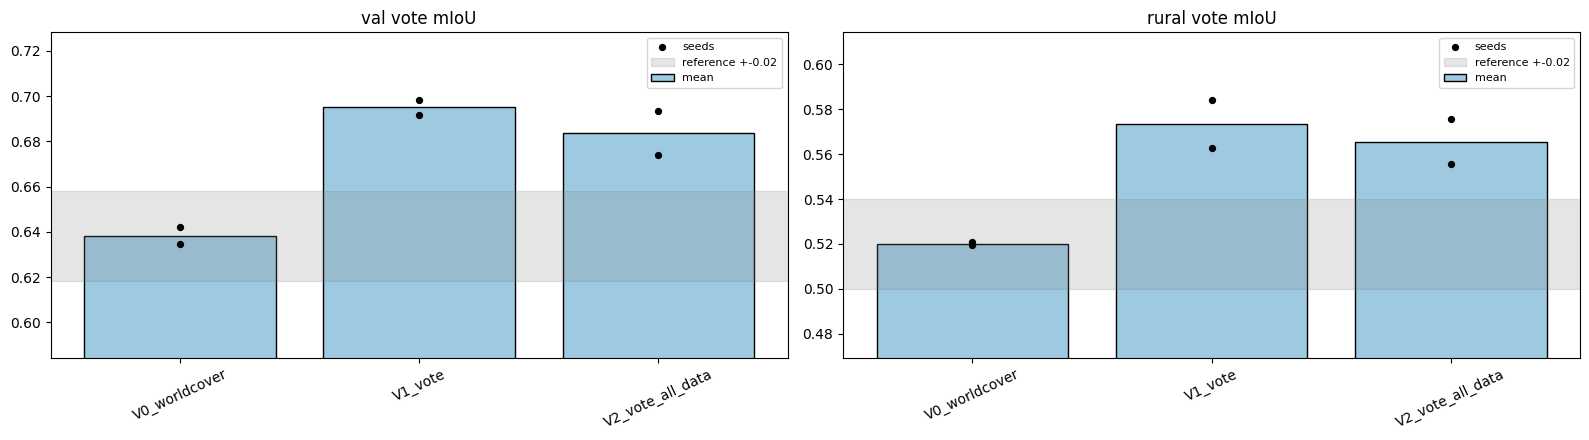

In [15]:
metrics = ["val vote mIoU", "val worldcover mIoU", "rural vote mIoU", "rural mIoU", "rural tolerant mIoU",
           "rural tolerant OA", "rural mIoU smoothed", "rural mIoU all", "test mIoU all sites",
           "flicker %", "flicker smoothed %"]
g = runs.groupby("experiment", sort=False)
summary = g[metrics].mean()
summary["val spread"] = g[DECIDE_BY].agg(lambda v: v.max() - v.min())
summary["rural spread"] = g["rural mIoU"].agg(lambda v: v.max() - v.min())
summary[["parameters M", "s per epoch", "epochs", "train-val gap"]] = g[["parameters M", "s per epoch", "epochs",
                                                                        "train-val gap"]].mean()
ref = summary.loc[REFERENCE] if REFERENCE in summary.index else None
if ref is not None:
    summary["val vs reference"] = summary[DECIDE_BY] - ref[DECIDE_BY]
    summary["rural vs reference"] = summary["rural vote mIoU"] - ref["rural vote mIoU"]
    summary["beats reference"] = summary["val vs reference"] > NOISE
summary.to_csv(OUT / "summary.csv")
print("4th iteration (WorldCover labels): Y0 val 0.735, rural 0.663; Y3 rural 0.659 (Crop 0.696, Grassland 0.681)")
print(f"mean over {len(SEEDS)} seeds; spread = best seed - worst seed. Decision: mean val mIoU "
      f"(rural test only reported); a change counts only if it beats {REFERENCE} by more than {NOISE}.")
display(summary.round(3))

per_class = g[[f"IoU {c}" for c in CLASS_NAMES]].mean().T
per_class.index = CLASS_NAMES
print("rural test IoU per class (raw maps, agreement pixels, mean over seeds):")
display(per_class.round(3))
per_class_vote = g[[f"vote IoU {c}" for c in CLASS_NAMES]].mean().T
per_class_vote.index = CLASS_NAMES
print("rural test IoU per class on the VOTE labels (mean over seeds):")
display(per_class_vote.round(3))
per_class_vote.to_csv(OUT / "per_class_rural_IoU_vote.csv")
per_class.to_csv(OUT / "per_class_rural_IoU.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
names = list(summary.index)
for ax, metric in zip(axes, [DECIDE_BY, "rural vote mIoU"]):
    ax.bar(names, summary[metric], color="#9ecae1", edgecolor="black", label="mean")
    for k, name in enumerate(names):
        vals = runs[runs.experiment == name][metric]
        ax.scatter([k] * len(vals), vals, color="black", zorder=3, s=18, label="seeds" if k == 0 else None)
    if ref is not None:
        ax.axhspan(ref[metric] - NOISE, ref[metric] + NOISE, color="grey", alpha=0.2, label=f"reference +-{NOISE}")
    lo = runs[metric].min()
    ax.set_ylim(max(0, lo - 0.05), min(1, runs[metric].max() + 0.03))
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "comparison.png", dpi=120)
plt.show()

### 9.2 Validation curves

Validation mIoU per epoch for every run. Look for: a configuration that keeps improving when the others stop (it might need more epochs), or one that peaks early and falls (overfitting).

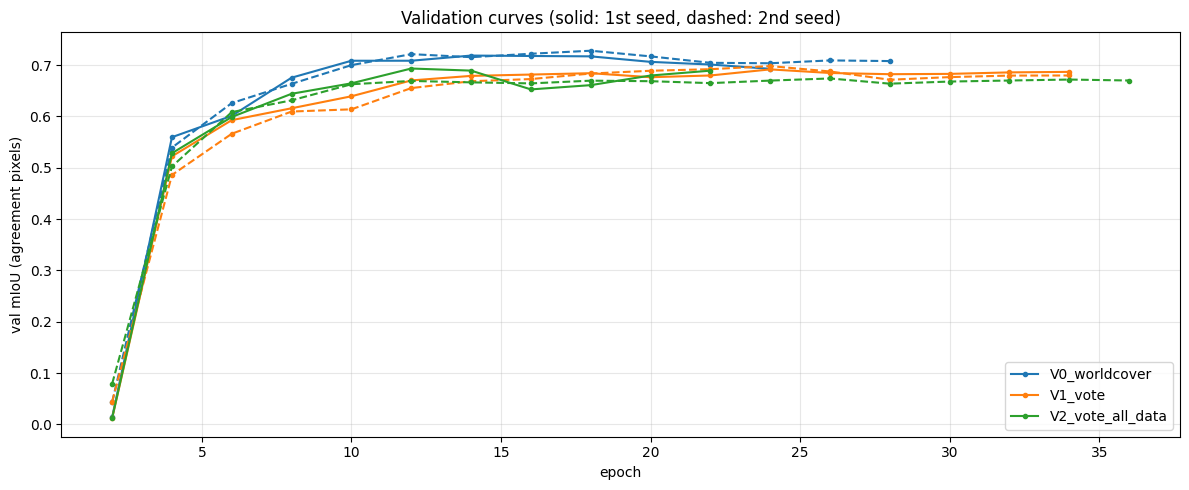

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.tab10.colors
for k, name in enumerate(CONFIGS):
    for j, seed in enumerate(SEEDS):
        h = histories.get(f"{name}_s{seed}")
        if h is not None:
            v = h.dropna(subset=["val_mIoU"])
            ax.plot(v.epoch, v.val_mIoU, color=colors[k % 10], ls="-" if j == 0 else "--",
                    marker="o", ms=3, label=name if j == 0 else None)
ax.set_xlabel("epoch")
ax.set_ylabel("val mIoU (agreement pixels)")
ax.set_title("Validation curves (solid: 1st seed, dashed: 2nd seed)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "val_curves.png", dpi=120)
plt.show()

### 9.3 The best configuration

The configuration with the best mean val mIoU and, of its seeds, the run with the best val mIoU. Its scores per region (compare with `Iter2_Test_1_Full`, printed above the table) and its confusion matrix on the rural test sites (row-normalised: recall on the diagonal).

best configuration by mean val mIoU: V1_vote (run V1_vote_s7)
it beats the reference by more than the noise: yes
winner per region (Iter2_Test_1_Full: africa 0.492, asia 0.656, europe 0.654, n_america 0.569, oceania 0.441, s_america 0.584):


,patches,OA,mIoU,mIoU smoothed,flicker %
region,,,,,
africa,64,0.833,0.484,0.485,2.923
asia,73,0.861,0.642,0.642,1.749
europe,32,0.960,0.659,0.660,0.606
n_america,48,0.867,0.631,0.633,2.428
oceania,16,0.960,0.400,0.401,0.317
s_america,32,0.876,0.563,0.564,1.082


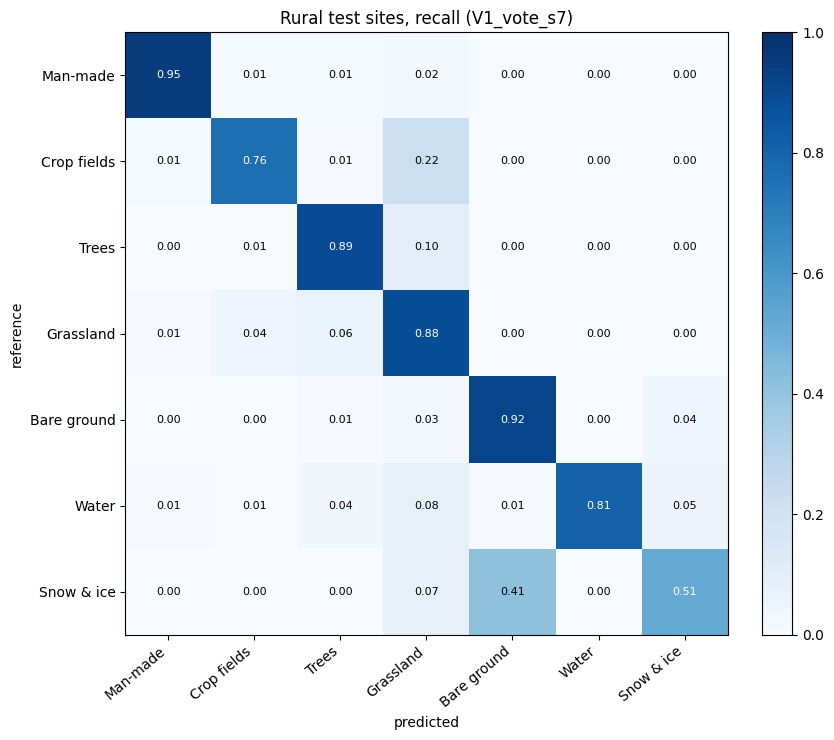

In [17]:
WINNER = summary[DECIDE_BY].idxmax()
win_runs = runs[runs.experiment == WINNER]
WINNER_RUN = win_runs.loc[win_runs[DECIDE_BY].idxmax(), "run"]
WINNER_CFG = CONFIGS[WINNER]
BEATS = bool(summary.loc[WINNER].get("beats reference", False)) if WINNER != REFERENCE else False
print(f"best configuration by mean val mIoU: {WINNER} (run {WINNER_RUN})")
print("it beats the reference by more than the noise:" if WINNER != REFERENCE else "the reference itself is best:",
      "yes" if BEATS else "no, keep Iter2_Test_1_Full as the final model")

model = UNet(input_channels(VARIANT), N_CLASSES, WINNER_CFG["encoder"], pretrained=False).to(
    DEVICE, memory_format=torch.channels_last)
model.load_state_dict(torch.load(RUNS_DIR / f"{WINNER_RUN}.pt", map_location=DEVICE))
model.eval()
results_rural = evaluate_year(model, "test", VARIANT, RURAL_IDS)
results_all = evaluate_year(model, "test", VARIANT)
USE_SMOOTHING = results_rural["smooth"]["mIoU"] >= results_rural["raw"]["mIoU"]


def group_scores(column):
    rows = []
    for group, df in index["test"].groupby(column):
        r = evaluate_year(model, "test", VARIANT, df.index.to_numpy())
        rows.append({column: group, "patches": len(df), "OA": r["raw"]["OA"], "mIoU": r["raw"]["mIoU"],
                     "mIoU smoothed": r["smooth"]["mIoU"], "flicker %": r["flicker"]["raw"] * 100})
    return pd.DataFrame(rows).set_index(column).round(3)


print("winner per region (Iter2_Test_1_Full: africa 0.492, asia 0.656, europe 0.654, n_america 0.569, "
      "oceania 0.441, s_america 0.584):")
display(group_scores("region"))

conf = results_rural["confusion"].astype(np.float64)
norm = conf / conf.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(norm, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, f"{norm[i, j]:.2f}", ha="center", va="center", color="white" if norm[i, j] > 0.5 else "black",
                fontsize=8)
ax.set_xticks(range(N_CLASSES), CLASS_NAMES, rotation=40, ha="right")
ax.set_yticks(range(N_CLASSES), CLASS_NAMES)
ax.set_xlabel("predicted")
ax.set_ylabel("reference")
ax.set_title(f"Rural test sites, recall ({WINNER_RUN})")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix_winner.png", dpi=120)
plt.show()

### 9.4 Class bias for Water and Man-made (no training)

Water is over-predicted (test precision 0.59, recall 0.74): dark, smooth radar returns from radar shadow, wet soil or dark forest look like open water. A per-class **offset on the log-probabilities** shifts the decision: a negative Water offset means "say Water only when clearly more likely than the alternatives".

- The offsets are tuned on **val** (all 12 months, the same smoothing as the model card), one class after the other (`BIAS_CLASSES`), over `BIAS_GRID`; an offset is kept only if val mIoU rises by more than `BIAS_MIN_GAIN`.
- The test set is used only to report the effect.
- Tuned for the winner and for `Iter2_Test_1_Full` (the final model used by the prototype), if its weights are in `Weights/Iter2_Test_1_Full/`.
- Stored in the model card as `class_logit_bias` (one value per class); the prototype adds it before choosing the class.


In [18]:
def bias_confusions(model, split, ids, biases, smooth):
    """Confusion matrix (agreement pixels) per candidate bias vector, one pass over the patches."""
    model.eval()
    confs = [torch.zeros(N_CLASSES, N_CLASSES, dtype=torch.long, device=DEVICE) for _ in biases]
    chunk_size = max(1, 2 * BATCH // 12)
    ids = [int(i) for i in ids]
    for b in range(0, len(ids), chunk_size):
        chunk = ids[b:b + chunk_size]
        probs = predict_year(model, split, VARIANT, chunk)
        if smooth:
            probs = smooth_months(probs)
        logp = probs.clamp_min(1e-8).log()
        y = torch.as_tensor(Y[split][chunk], device=DEVICE).long()[:, None].expand(-1, 12, -1, -1)
        target, agree = split_label(y)
        target_agree = target.masked_fill(~agree, IGNORE)
        for conf, bias in zip(confs, biases):
            pred = (logp + bias.view(1, 1, -1, 1, 1)).argmax(2)
            update_confusion(conf, pred, target_agree)
    return [metrics_from_confusion(c) for c in confs]


def tune_bias(model, smooth, label):
    """Coordinate search on val over BIAS_CLASSES; returns the bias vector and a table of its effect."""
    bias = torch.zeros(N_CLASSES, device=DEVICE)
    val_ids = range(len(X["val"]))
    best = bias_confusions(model, "val", val_ids, [bias], smooth)[0]["mIoU"]
    start = best
    for name in BIAS_CLASSES:
        k = CLASS_NAMES.index(name)
        candidates = []
        for v in BIAS_GRID:
            cand = bias.clone()
            cand[k] = v
            candidates.append(cand)
        scores = [m["mIoU"] for m in bias_confusions(model, "val", val_ids, candidates, smooth)]
        j = int(np.argmax(scores))
        if scores[j] > best + BIAS_MIN_GAIN:
            bias, best = candidates[j], scores[j]
        print(f"{label}: {name} offset {bias[k].item():+.2f} (val mIoU {best:.4f})")
    before, after = bias_confusions(model, "test", RURAL_IDS, [torch.zeros_like(bias), bias], smooth)
    k_w = CLASS_NAMES.index("Water")
    table = pd.DataFrame({
        "val mIoU": [start, best],
        "rural test mIoU": [before["mIoU"], after["mIoU"]],
        "Water IoU": [before["IoU"][k_w], after["IoU"][k_w]],
        "Water precision": [before["precision"][k_w], after["precision"][k_w]],
        "Water recall": [before["recall"][k_w], after["recall"][k_w]],
        **{f"IoU {c}": [before["IoU"][i], after["IoU"][i]] for i, c in enumerate(CLASS_NAMES) if c != "Water"},
    }, index=["no bias", "with bias"]).round(4)
    return bias.cpu().numpy().round(3).tolist(), table


WINNER_BIAS, bias_table = tune_bias(model, USE_SMOOTHING, WINNER_RUN)
print("class_logit_bias of the winner:", dict(zip(CLASS_NAMES, WINNER_BIAS)))
display(bias_table)
bias_table.to_csv(OUT / "class_bias_winner.csv")

# the final model of the prototype: the same tuning, so the Water fix is available without retraining
ITER2_DIR = ROOT / "Weights" / "Iter2_Test_1_Full"
ITER2_BIAS = None
if (ITER2_DIR / "final_model.pt").exists() and (ITER2_DIR / "model_card.json").exists():
    iter2_card = json.load(open(ITER2_DIR / "model_card.json"))
    same_norm = (np.allclose(iter2_card["channel_mean"], CH_MEAN, atol=1e-3)
                 and np.allclose(iter2_card["stats_mean"], STAT_MEAN, atol=1e-3))
    if not same_norm:
        print("Iter2_Test_1_Full uses a different normalisation than this notebook's reference: not tuned")
    else:
        iter2 = UNet(input_channels(VARIANT), N_CLASSES, "resnet34", pretrained=False).to(
            DEVICE, memory_format=torch.channels_last)
        state = torch.load(ITER2_DIR / "final_model.pt", map_location=DEVICE)
        iter2.load_state_dict({k.removeprefix("module."): v for k, v in state.items() if k != "n_averaged"})
        iter2_smooth = iter2_card.get("temporal_smoothing", "none") != "none"
        ITER2_BIAS, iter2_table = tune_bias(iter2, iter2_smooth, "Iter2_Test_1_Full")
        print("class_logit_bias of Iter2_Test_1_Full:", dict(zip(CLASS_NAMES, ITER2_BIAS)))
        display(iter2_table)
        iter2_table.to_csv(OUT / "class_bias_iter2.csv")
        del iter2
        torch.cuda.empty_cache()
else:
    print("Weights/Iter2_Test_1_Full not found on this machine: its class bias is not tuned")


class_logit_bias of the winner: {'Man-made': 0.0, 'Crop fields': 0.0, 'Trees': 0.0, 'Grassland': 0.0, 'Bare ground': 0.0, 'Water': 0.0, 'Snow & ice': 0.0}


,val mIoU,rural test mIoU,Water IoU,Water precision,Water recall,IoU Man-made,IoU Crop fields,IoU Trees,IoU Grassland,IoU Bare ground,IoU Snow & ice
no bias,0.7458,0.676,0.4651,0.5235,0.8065,0.7639,0.6883,0.8365,0.7197,0.8737,0.3852
with bias,0.7458,0.676,0.4651,0.5235,0.8065,0.7639,0.6883,0.8365,0.7197,0.8737,0.3852


Weights/Iter2_Test_1_Full not found on this machine: its class bias is not tuned


## 10. Export of the best run

`best_model.pt` + `model_card.json` in `Weights/<RUN_NAME>/`, with `class_logit_bias` (section 9.4) and `training_years`, in the same format as the 2nd iteration plus `encoder`, `experiment`, `run`, `training` and `beats_reference`. The prototype (`prototype/model.py`) builds the encoder named in the card, so it can load any run of this notebook.

**`final_model.pt` of `Iter2_Test_1_Full` stays the final model** unless `beats_reference` is true. Even then, run the prototype's rural tests with the new model before switching. The whole folder is zipped for one download.
**`Iter2_Test_1_Full` with its class bias** is written to `Weights/Iter2_Test_1_Full_bias/` (a copy of `final_model.pt` and its model card plus `class_logit_bias`), so the prototype can use the Water fix with the current final model: choose that folder under *Advanced → Other run folder*. The original folder is not changed.


In [19]:
model_card = {
    "iteration": 2,   # input format of the 2nd iteration (the prototype reads it this way)
    "experiment": WINNER,
    "run": WINNER_RUN,
    "beats_reference": BEATS,
    "variant": VARIANT_NAME,
    "n_months": VARIANT["n_months"],
    "in_channels": input_channels(VARIANT),
    "encoder": WINNER_CFG["encoder"],
    "training": WINNER_CFG,
    "channels_per_month": ["VV_dB", "VH_dB", "VV_minus_VH_dB"],
    "month_window": "target month and the previous n_months-1 months, oldest first (wrapping around the year)",
    "static_channels": STAT_NAMES,
    "channel_order": "monthly channels (oldest month first), then static_channels",
    "s1_preprocessing": S1_PREPROCESSING,
    "stats_definition": "over the 12 months in dB: VV mean, VH mean, (VV-VH) mean, VV 2nd lowest, VV 2nd highest, "
                        "VH 2nd lowest, VH 2nd highest, VH std, share of valid months with VV < "
                        f"{WATER_DB} dB (missing months filled with the pixel mean before sorting); "
                        "standardised with stats_mean/std",
    "stats_mean": STAT_MEAN.tolist(),
    "stats_std": STAT_STD.tolist(),
    "channel_mean": CH_MEAN.tolist(),
    "channel_std": CH_STD.tolist(),
    "temporal_smoothing": ("mean softmax of months t-1, t, t+1 (wrapping) before argmax" if USE_SMOOTHING else "none"),
    "label": ("majority vote of ESA WorldCover 2021, Dynamic World and Esri LULC of the radar year (class of at least "
              "2 maps, weight 1; WorldCover where all differ, weight " f"{WINNER_CFG['disagree_weight']})"
              if WINNER_CFG["labels"] == "vote" else
              "ESA WorldCover 2021 on all pixels; Dynamic World agreement pixels weight 1, others "
              f"{WINNER_CFG['disagree_weight']}; scores on agreement pixels"),
    "training_labels": WINNER_CFG["labels"],
    "test_rural_mIoU_vote_labels": float(summary.loc[WINNER, "rural vote mIoU"]),
    "test_rural_mIoU_tolerant": float(summary.loc[WINNER, "rural tolerant mIoU"]),
    "ema_decay": EMA_DECAY,
    "nan_fill_after_standardisation": 0.0,
    "db_decoding": {"db_min": DB_MIN, "db_step": DB_STEP, "nodata_code": 0},
    "class_names": CLASS_NAMES,
    "class_colors": CLASS_COLORS,
    "patch_size": PATCH,
    "architecture": f"UNet with a {WINNER_CFG['encoder']} encoder ({NOTEBOOK})",
    "weights": "best_model.pt",
    "test_rural_mIoU": results_rural["raw"]["mIoU"],
    "test_rural_mIoU_smoothed": results_rural["smooth"]["mIoU"],
    "test_rural_flicker": results_rural["flicker"],
    "test_mIoU": results_all["raw"]["mIoU"],
    "training_years": list(WINNER_CFG["years"]),
    "training_new_sites": WINNER_CFG["new_sites"],
    "class_logit_bias": WINNER_BIAS,
    "class_logit_bias_note": "added to the log of the (smoothed) class probabilities before argmax; tuned on val "
                             f"for {BIAS_CLASSES} ({NOTEBOOK}, section 9.4)",
}
shutil.copy(RUNS_DIR / f"{WINNER_RUN}.pt", OUT / "best_model.pt")
json.dump(model_card, open(OUT / "model_card.json", "w"), indent=2)
archive = shutil.make_archive(str(OUT), "zip", OUT)
print({k: v for k, v in model_card.items() if k not in ("stats_mean", "stats_std")})
print("saved:", sorted(p.name for p in OUT.iterdir()))
print("archive:", archive)
if ITER2_BIAS is not None:
    bias_dir = ROOT / "Weights" / "Iter2_Test_1_Full_bias"
    bias_dir.mkdir(exist_ok=True)
    shutil.copy(ITER2_DIR / "final_model.pt", bias_dir / "final_model.pt")
    json.dump(iter2_card | {"class_logit_bias": ITER2_BIAS,
                            "class_logit_bias_note": "added to the log of the (smoothed) class probabilities before "
                                                     f"argmax; tuned on val for {BIAS_CLASSES} ({NOTEBOOK}, section 9.4)"},
              open(bias_dir / "model_card.json", "w"), indent=2)
    print("Iter2_Test_1_Full with class bias:", bias_dir)


{'iteration': 2, 'experiment': 'V1_vote', 'run': 'V1_vote_s7', 'beats_reference': True, 'variant': 'month_year', 'n_months': 1, 'in_channels': 12, 'encoder': 'resnet34', 'training': {'encoder': 'resnet34', 'pretrained': True, 'optimizer': 'adamw', 'lr': 0.0006, 'weight_decay': 0.05, 'lovasz_weight': 0.5, 'disagree_weight': 0.5, 'label_smoothing': 0.1, 'bootstrap_beta': 1.0, 'years': (2021,), 'new_sites': False, 'labels': 'vote'}, 'channels_per_month': ['VV_dB', 'VH_dB', 'VV_minus_VH_dB'], 'month_window': 'target month and the previous n_months-1 months, oldest first (wrapping around the year)', 'static_channels': ['VV mean', 'VH mean', 'VV-VH mean', 'VV low', 'VV high', 'VH low', 'VH high', 'VH std', 'water months'], 'channel_order': 'monthly channels (oldest month first), then static_channels', 's1_preprocessing': 'S1_GRD IW VV+VH asc+desc; gamma0 terrain flattening (Vollrath 2020 volume model, GLO-30); layover/shadow/incidence 31-45 deg masked; monthly linear mean; dB; no spatial fil